# Capstone Project
## Predicting Employee Attrition Risk for Proactive Retention Strategies

HR teams cannot review every employee with the same level of attention. I wanted to find out whether information available in monthly workforce records could help them decide where to begin a supportive retention review. My question is: **Can these records identify employees who are more likely to have a voluntary exit during the next six months?**

I treat this as a binary classification problem: `1` means a qualifying voluntary exit within six months, and `0` means no qualifying exit in that window. The goal is a useful ranking and a manageable review list. In this run, a simpler Gradient Boosting model meets my case-capture target and development-performance safeguard, with a more concentrated review list than Logistic Regression.

The notebook follows the decisions I made along the way: checking the data, respecting the timeline, testing inputs and models, and translating the results into HR workload. The score supports review; it does not decide what should happen to an individual employee.

In [1]:
import hashlib
import warnings

# Import tools for checking the data and presenting the results.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Import the preparation, modeling and evaluation tools used below.
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

from sklearn.base import clone


## 1. Starting with Monthly Workforce Records

I built the SQL Server procedure `Attrition.Employee_Comp_Monthly` to assemble workforce information at monthly snapshot dates and attach the six-month voluntary-exit outcome. This gives me a consistent starting point for comparing earlier and later periods.

The source contains about 3.3 million employee-month records across three years. An employee can appear in several months, so this is not a dataset of 3.3 million different people. Employee IDs are masked and excluded from the model inputs. The underlying workforce data remain private. This submission retains aggregate outputs for review; rerunning the SQL-based training requires authorized access and a locally configured connection.

In [2]:
# Use Windows authentication; keep local server settings out of the repository.
import json
import os
from pathlib import Path
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# An explicit environment URL takes priority over the local connection file.
connection_url = os.environ.get("ATTRITION_SQLALCHEMY_URL")
if not connection_url:
    config_candidates = [
        Path("sql_connection.local.json"),
        Path("Final Report") / "sql_connection.local.json",
        Path("Capstone") / "Final Report" / "sql_connection.local.json",
    ]
    config_path = next((p for p in config_candidates if p.is_file()), None)
    if config_path is None:
        raise RuntimeError(
            "Open Jupyter in the Final Report folder containing "
            "sql_connection.local.json, or set ATTRITION_SQLALCHEMY_URL. "
            "Database access is required to reload the private workforce data."
        )
    settings = json.loads(config_path.read_text(encoding="utf-8"))
    connection_url = URL.create(
        "mssql+pyodbc",
        host=settings["server"],
        port=int(settings["port"]),
        database=settings["database"],
        query={
            "driver": settings.get("driver", "ODBC Driver 17 for SQL Server"),
            "trusted_connection": "yes",
        },
    )

engine = create_engine(connection_url, connect_args={"timeout": 15}, pool_pre_ping=True)
sql = """
EXEC Attrition.Employee_Comp_Monthly
    @snapshot_months_back = 36,
    @mask_nuid = 1,
    @regions = 'Northern California,Executives';
"""
df = pd.read_sql(sql, engine)
print("Rows loaded:", f"{len(df):,}")
print("Columns loaded:", df.shape[1])
print("Snapshots loaded:", df["snapshot_date"].nunique())

Rows loaded: 3,273,117
Columns loaded: 30
Snapshots loaded: 36


In [3]:
# Check the intended grain: one record per employee per snapshot month.
employee_month_duplicate_count = int(
    df.duplicated(subset=["snapshot_date", "nuid"]).sum()
)
print("Duplicate employee-month records:", f"{employee_month_duplicate_count:,}")

if employee_month_duplicate_count > 0:
    raise ValueError(
        "The source contains duplicate employee-month records and must be corrected before modeling."
    )


Duplicate employee-month records: 0


## 2. Understanding the Data Before Modeling

I began by checking the size, dates, field types, missing values and numeric ranges. The refreshed source contains **3,273,117 employee-month records across 36 snapshots**, from October 2023 through September 2026. These checks help me distinguish an unusual employee profile from a possible source-data issue.

Only records with complete six-month outcomes can support model evaluation. The maturity check in Section 3 retains **2,548,054 records through January 2026**. From this eligible history, the time-based design uses 1,272,081 earlier records for training, 91,167 for validation and 90,988 for the historical holdout. The full eligible pool is larger than the subset used in those comparisons.

Voluntary exits are uncommon, so a model could look accurate simply by predicting no exit for almost everyone. I therefore focus on how well it ranks records and what its review list captures. The later evaluation sections explain those measures in terms of cases found and employees reviewed.

In [4]:
# Record the starting size before filtering for complete outcomes.
df.shape

(3273117, 30)

In [5]:
# See which candidate inputs have missing values before choosing a treatment.
missing_value_review_columns = [
    "annual_salary",
    "compa_ratio",
    "performance_rating",
    "tenure_months",
    "low_performer",
    "mgr_team_size",
    "mgr_avg_team_tenure",
    "mgr_low_perf_pct",
    "mgr_attrition_6mo_rate",
    "mgr_attrition_12mo_rate",
    "region",
    "entity",
    "service_area_new",
    "attrition_6mo_voluntary",
]
missing_value_summary = (
    (df[missing_value_review_columns].isna().mean() * 100)
    .rename("missing_value_percent")
    .sort_values(ascending=False)
    .to_frame()
)
display(missing_value_summary.round(1))


,missing_value_percent
low_performer,24.1
performance_rating,24.1
attrition_6mo_voluntary,22.2
mgr_attrition_12mo_rate,17.8
mgr_attrition_6mo_rate,11.9
mgr_low_perf_pct,2.4
compa_ratio,0.9
annual_salary,0.9
service_area_new,0.0
mgr_team_size,0.0


Missing values need two different treatments here. A missing predictor, such as a numeric workforce field, can be replaced using a value learned from training data. A missing outcome means I do not know what happened during the six-month window; I cannot assign it as “no exit”.

I handle predictor replacements inside the modeling pipelines and check outcome completeness separately by snapshot month. This keeps later information out of training and avoids treating unavailable outcomes as evidence of retention.

In [6]:
# Use aggregate summaries rather than displaying employee-level examples.
summary_features = ["annual_salary", "tenure_months", "compa_ratio",
                    "performance_rating", "mgr_team_size"]
summary_labels = {
    "annual_salary": "Recorded annual salary (USD)",
    "tenure_months": "Employee tenure (months)",
    "compa_ratio": "Pay position relative to peers",
    "performance_rating": "Performance rating",
    "mgr_team_size": "Manager team size",
}
workforce_summary = df[summary_features].describe().T[
    ["mean", "25%", "50%", "75%", "max"]
].rename(index=summary_labels, columns={"mean": "Mean", "25%": "25th percentile",
    "50%": "Median", "75%": "75th percentile", "max": "Maximum"})
display(workforce_summary.round(2))

,Mean,25th percentile,Median,75th percentile,Maximum
Recorded annual salary (USD),106944.93,62929.65,94944.44,151967.46,2450000.06
Employee tenure (months),135.16,44.00,106.00,215.00,731.00
Pay position relative to peers,0.99,0.97,1.00,1.02,8.83
Performance rating,3.27,3.00,3.00,4.00,5.00
Manager team size,28.13,15.00,23.00,34.00,328.00


### Why a Rare Outcome Changes the Evaluation

Only about 1%–2% of records have a qualifying voluntary exit. That imbalance matters: getting most records right is easy if the model overlooks the smaller group HR wants to understand. I need to judge whether the ranking finds more exit cases than an untargeted review and how much work that requires.

I use two kinds of measures. **Average precision (AP)** summarizes precision across the ranking; **ROC-AUC** provides another view of how well the model separates the two outcomes. AP is the ranking summary used for development here, rather than a trapezoidal calculation of area under the precision-recall curve.

For the actual review list, **recall** tells me what share of later voluntary exits was captured, **precision** tells me what share of listed records had that exit, and **lift** compares the list's exit share with the workforce rate. The number and percentage flagged translate those results into HR workload. Validation chooses the cutoff; the historical holdout checks the fixed choice later.

In [7]:
# Confirm the available time period before separating training, validation, and test.
df['snapshot_date'].min(), df['snapshot_date'].max()

(datetime.date(2023, 10, 31), datetime.date(2026, 9, 30))

### Exploratory Findings Carried into Modeling

The [EDA summary](../EDA/README.md) showed that six-month voluntary exits were uncommon, around 1.3% of fully observed employee-months. Employees who later left had roughly three years of median tenure, compared with nearly nine years among those without the target exit. Pay-position differences were smaller. Job-family and department rates varied, but workforce mix and repeated monthly records limit causal interpretation.

An earlier EDA baseline had about 3.1% validation average precision. It used a different feature and evaluation setup, so I do not treat it as a directly comparable competitor in the final three-model table. Those findings motivated the focus on tenure, pay definitions, rare-outcome metrics and calendar-based comparisons. Unusual pay values remain questions for data review, rather than automatic evidence that someone is underpaid.

## 3. Making Sure the Forecast Uses the Right Information

A forecast should use only what was known at its snapshot date. I remove termination details and direct identifiers from the predictors and check that earlier six-month outcome windows end before the next forecast period. This addresses **data leakage**, where future information makes a model appear more useful than it would be in practice.

I also need complete outcomes. Simply having a September 2026 workforce snapshot does not prove that every earlier six-month label is available. I compare the latest snapshot minus six months with the latest eligible month that has a target for every employee, then use the earlier cutoff. For this run, that is **January 31, 2026**.

This leaves **2,548,054 labeled records** and excludes **725,063 recent or incomplete-coverage records**. There are no missing targets in the retained history. I exclude whole recent snapshots rather than fill their unknown outcomes with zero. If an incomplete month appears inside the retained history, the check stops so the source issue can be investigated.

In [8]:
import pandas as pd
import numpy as np

TARGET_COL = "attrition_6mo_voluntary"
OUTCOME_WINDOW_MONTHS = 6


def shift_month_end(date_value, months):
    """Match the SQL target's month-end outcome boundary."""
    return (pd.Timestamp(date_value).to_period("M") + months).to_timestamp("M")


def determine_label_maturity(frame, target_col, outcome_window_months=6):
    """Require elapsed time and complete snapshot-wide label coverage."""
    if frame.empty:
        raise ValueError("No workforce records are available for modeling.")
    dates = pd.to_datetime(frame["snapshot_date"], errors="raise")
    if dates.isna().any() or not dates.dt.is_month_end.all():
        raise ValueError("Every workforce snapshot must have a valid month-end date.")
    target = frame[target_col]
    if not target.dropna().isin([0, 1]).all():
        raise ValueError("The attrition target must contain only 0, 1, or unavailable labels.")

    latest_snapshot = dates.max()
    calendar_cutoff = shift_month_end(latest_snapshot, -outcome_window_months)
    coverage = (pd.DataFrame({"snapshot_date": dates, "target": target})
                .groupby("snapshot_date")["target"].agg(rows="size", labeled_rows="count"))
    coverage["missing_targets"] = coverage["rows"] - coverage["labeled_rows"]
    coverage["calendar_eligible"] = coverage.index <= calendar_cutoff
    complete_dates = coverage.index[
        coverage["calendar_eligible"] & coverage["missing_targets"].eq(0)]
    if len(complete_dates) == 0:
        raise ValueError("No calendar-eligible snapshot has complete six-month outcomes.")
    latest_complete_snapshot = complete_dates.max()
    maturity_cutoff = min(calendar_cutoff, latest_complete_snapshot)
    coverage["retained_for_modeling"] = coverage.index <= maturity_cutoff

    incomplete_history = coverage.loc[
        coverage["retained_for_modeling"] & coverage["missing_targets"].gt(0)]
    if not incomplete_history.empty:
        bad_dates = ", ".join(incomplete_history.index.strftime("%Y-%m-%d"))
        raise ValueError(
            "Incomplete targets inside the retained modeling history: " + bad_dates
            + ". Correct the source; do not replace unavailable labels with retention.")
    return latest_snapshot, calendar_cutoff, latest_complete_snapshot, maturity_cutoff, coverage


df = df.copy()
df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])
(latest_available_snapshot, calendar_maturity_cutoff, latest_complete_label_snapshot,
 label_maturity_cutoff, label_coverage_summary) = determine_label_maturity(
    df, TARGET_COL, OUTCOME_WINDOW_MONTHS)

# Keep future outcome information and identifiers out of the predictors.
leakage_cols = ["nuid", "manager_nuid", "termination_date"]
df_model_all = df.drop(columns=leakage_cols, errors="ignore").copy()
df_model = df_model_all.loc[
    df_model_all["snapshot_date"] <= label_maturity_cutoff].copy()

dropped_immature_rows = len(df_model_all) - len(df_model)
missing_mature_targets = int(df_model[TARGET_COL].isna().sum())
if df_model.empty or missing_mature_targets > 0:
    raise ValueError("The mature modeling data must contain complete six-month outcomes.")

print("Latest available workforce snapshot:", latest_available_snapshot.date())
print("Calendar-only maturity ceiling:", calendar_maturity_cutoff.date())
print("Latest fully labeled eligible snapshot:", latest_complete_label_snapshot.date())
print("Effective label maturity cutoff:", label_maturity_cutoff.date())
print("Latest retained snapshot:", df_model["snapshot_date"].max().date())
print("Rows available before maturity filter:", f"{len(df_model_all):,}")
print("Rows retained for modeling:", f"{len(df_model):,}")
print("Recent or incomplete-coverage rows excluded:", f"{dropped_immature_rows:,}")
print("Missing targets among retained rows:", f"{missing_mature_targets:,}")
display(label_coverage_summary.tail(12))

Latest available workforce snapshot: 2026-09-30
Calendar-only maturity ceiling: 2026-03-31
Latest fully labeled eligible snapshot: 2026-01-31
Effective label maturity cutoff: 2026-01-31
Latest retained snapshot: 2026-01-31
Rows available before maturity filter: 3,273,117
Rows retained for modeling: 2,548,054
Recent or incomplete-coverage rows excluded: 725,063
Missing targets among retained rows: 0


,rows,labeled_rows,missing_targets,calendar_eligible,retained_for_modeling
snapshot_date,,,,,
2025-10-31,91339,91339,0,True,True
2025-11-30,91136,91136,0,True,True
2025-12-31,90999,90999,0,True,True
2026-01-31,90988,90988,0,True,True
2026-02-28,90840,0,90840,True,False
2026-03-31,90881,0,90881,True,False
2026-04-30,90695,0,90695,False,False
2026-05-31,90444,0,90444,False,False
2026-06-30,90785,0,90785,False,False


## 4. Adding a Few Business-Relevant Inputs

I wanted to test whether some combinations of the existing information were more useful than individual fields alone. I added an indicator for a pay ratio below 1, an indicator for recent manager-team turnover, and an interaction between pay position and tenure. An **interaction** lets the model represent a relationship that may vary with another input.

These are hypotheses about prediction. A pay ratio below 1 means the employee is below the source's benchmark; it does not by itself establish that the employee is underpaid. The pay definition needs to be confirmed before interpreting the result for HR.

In [9]:
# Flag compa-ratio below 1; confirm the underlying peer-pay benchmark before HR interpretation.
df_model["underpaid_flag"] = (df_model["compa_ratio"] < 1).astype(int)

df_model["high_mgr_attrition"] = (
    df_model["mgr_attrition_12mo_rate"].fillna(0) > 0
).astype(int)

# Allow pay position and tenure to contribute jointly to the score.
df_model["compa_tenure_interaction"] = (
    df_model["compa_ratio"] * df_model["tenure_months"]
)

df_model = df_model.replace([np.inf, -np.inf], np.nan)

print("Feature engineering completed.")


Feature engineering completed.


## 5. Keeping the Evaluation in Calendar Order

I use earlier records to learn patterns and later records to evaluate them. Training covers **October 2023–November 2024**. **June 2025 validation** is where I choose the final model and review cutoff. **January 2026** provides a later historical check using that fixed choice. Month-end checks verify that each earlier outcome window finishes before the next forecast date.

These periods serve different purposes: training teaches the model, validation helps me choose how to use it, and the holdout checks the chosen approach on a later period. The January holdout has already been inspected in earlier project versions, so this is a historical replay. I still need a future untouched period with complete outcomes for confirmation.

In [10]:
# Limit inputs to workforce information available at the forecast date.
num_features = [
    "annual_salary",
    "compa_ratio",
    "performance_rating",
    "tenure_months",
    "low_performer",
    "mgr_team_size",
    "mgr_avg_team_tenure",
    "mgr_low_perf_pct",
    "mgr_attrition_6mo_rate",
    "mgr_attrition_12mo_rate",
    "underpaid_flag",
    "high_mgr_attrition",
    "compa_tenure_interaction",
]

cat_features = [
    "region",
    "entity",
    "service_area_new",
]

model_features = num_features + cat_features
missing_features = [
    col
    for col in model_features + [TARGET_COL, "snapshot_date"]
    if col not in df_model.columns
]
if missing_features:
    raise ValueError(f"Missing required modeling columns: {missing_features}")

# Keep validation and historical-holdout outcome windows separate.
FORECAST_SPACING_MONTHS = OUTCOME_WINDOW_MONTHS + 1
snapshot_dates = np.array(sorted(df_model["snapshot_date"].dropna().unique()))
if len(snapshot_dates) < (2 * FORECAST_SPACING_MONTHS) + 3:
    raise ValueError("Not enough mature snapshot dates for fixed forecast evaluation.")

test_date = pd.Timestamp(snapshot_dates[-1])
validation_cutoff = test_date - pd.DateOffset(months=FORECAST_SPACING_MONTHS)
validation_candidates = [
    pd.Timestamp(date)
    for date in snapshot_dates
    if pd.Timestamp(date) <= validation_cutoff
]
if not validation_candidates:
    raise ValueError("No eligible Validation forecast snapshot was found.")
validation_date = max(validation_candidates)

train_cutoff = validation_date - pd.DateOffset(months=FORECAST_SPACING_MONTHS)
train_dates = np.array([
    date for date in snapshot_dates if pd.Timestamp(date) <= train_cutoff
])
valid_dates = np.array([validation_date.to_datetime64()])
test_dates = np.array([test_date.to_datetime64()])

train = df_model.loc[
    df_model["snapshot_date"].isin(train_dates)
].sort_values("snapshot_date").copy()
valid = df_model.loc[
    df_model["snapshot_date"].isin(valid_dates)
].sort_values("snapshot_date").copy()
test = df_model.loc[
    df_model["snapshot_date"].isin(test_dates)
].sort_values("snapshot_date").copy()

if train.empty or valid.empty or test.empty:
    raise ValueError("The fixed forecast split produced an empty dataset.")

# Verify that no evaluation period uses outcomes extending into the next forecast date.
train_outcome_end = shift_month_end(
    train["snapshot_date"].max(), OUTCOME_WINDOW_MONTHS
)
validation_outcome_end = shift_month_end(
    validation_date, OUTCOME_WINDOW_MONTHS
)
if train_outcome_end >= validation_date:
    raise ValueError("Training outcomes overlap the Validation forecast snapshot.")
if validation_outcome_end >= test_date:
    raise ValueError("Validation outcomes overlap the Test forecast snapshot.")

# Keep dates for the time split, but do not allow the models to use them as predictors.
X_train = train[model_features].reset_index(drop=True)
y_train = train[TARGET_COL].reset_index(drop=True)
train_snapshot_dates = train["snapshot_date"].reset_index(drop=True)

X_valid = valid[model_features].reset_index(drop=True)
y_valid = valid[TARGET_COL].reset_index(drop=True)
valid_snapshot_dates = valid["snapshot_date"].reset_index(drop=True)

X_test = test[model_features].reset_index(drop=True)
y_test = test[TARGET_COL].reset_index(drop=True)
test_snapshot_dates = test["snapshot_date"].reset_index(drop=True)

print("Train period:", train["snapshot_date"].min().date(), "to", train["snapshot_date"].max().date())
print("Train six-month outcome window ends:", train_outcome_end.date())
print("Validation forecast snapshot:", validation_date.date())
print("Validation six-month outcome window ends:", validation_outcome_end.date())
print("Test forecast snapshot:", test_date.date())
print("Outcome-window overlap check: PASSED")
print()
print("Train shape:", X_train.shape, "positive rate:", round(y_train.mean(), 5))
print("Validation shape:", X_valid.shape, "positive rate:", round(y_valid.mean(), 5))
print("Test shape (outcomes held for final evaluation):", X_test.shape)

# Report the shares produced by these calendar windows.
model_split_summary_df = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Records": [len(X_train), len(X_valid), len(X_test)],
    "Period": [
        f"{train['snapshot_date'].min():%b %Y}-{train['snapshot_date'].max():%b %Y}",
        f"{validation_date:%b %Y} snapshot",
        f"{test_date:%b %Y} snapshot",
    ],
})
model_split_summary_df["Share"] = (
    model_split_summary_df["Records"] / model_split_summary_df["Records"].sum()
)
display(model_split_summary_df)


Train period: 2023-10-31 to 2024-11-30
Train six-month outcome window ends: 2025-05-31
Validation forecast snapshot: 2025-06-30
Validation six-month outcome window ends: 2025-12-31
Test forecast snapshot: 2026-01-31
Outcome-window overlap check: PASSED

Train shape: (1272081, 16) positive rate: 0.01414
Validation shape: (91167, 16) positive rate: 0.01253
Test shape (outcomes held for final evaluation): (90988, 16)


,Dataset,Records,Period,Share
0,Training,1272081,Oct 2023-Nov 2024,0.874742
1,Validation,91167,Jun 2025 snapshot,0.062691
2,Test,90988,Jan 2026 snapshot,0.062568


In [11]:
# Confirm that training, validation, and test use the same feature columns.
for name, X_part in [("train", X_train), ("validation", X_valid), ("test", X_test)]:
    unexpected = sorted(set(X_part.columns) - set(model_features))
    missing = sorted(set(model_features) - set(X_part.columns))
    print(f"{name} columns: {X_part.shape[1]}")
    print("  unexpected columns:", unexpected)
    print("  missing columns:", missing)

assert "snapshot_date" not in X_train.columns
assert "termination_date" not in X_train.columns
assert "nuid" not in X_train.columns
assert "manager_nuid" not in X_train.columns


train columns: 16
  unexpected columns: []
  missing columns: []
validation columns: 16
  unexpected columns: []
  missing columns: []
test columns: 16
  unexpected columns: []
  missing columns: []


### 5.1 Setting a Simple Starting Point

Before fitting a model, I ask what I would achieve without one. Predicting “no voluntary exit” for everyone would produce high accuracy but find none of the exit cases. An untargeted ranking has expected average precision equal to the observed exit rate. These **baselines** give me a reference for judging whether the model adds useful information.

In [12]:
# Establish simple references before comparing trained models.
baseline_summary = pd.DataFrame({
    "data_period": ["Training", "Validation"],
    "records": [len(y_train), len(y_valid)],
    "observed_attrition_cases": [int(y_train.sum()), int(y_valid.sum())],
    "attrition_rate": [float(y_train.mean()), float(y_valid.mean())],
})
baseline_summary["majority_class_accuracy"] = 1 - baseline_summary["attrition_rate"]
baseline_summary["majority_class_recall"] = 0.0
baseline_summary["random_ranking_average_precision"] = baseline_summary["attrition_rate"]

display(
    baseline_summary.style.format({
        "records": "{:,}",
        "observed_attrition_cases": "{:,}",
        "attrition_rate": "{:.2%}",
        "majority_class_accuracy": "{:.2%}",
        "majority_class_recall": "{:.1%}",
        "random_ranking_average_precision": "{:.2%}",
    })
)


,data_period,records,observed_attrition_cases,attrition_rate,majority_class_accuracy,majority_class_recall,random_ranking_average_precision
0,Training,"1,272,081","17,984",1.41%,98.59%,0.0%,1.41%
1,Validation,"91,167","1,142",1.25%,98.75%,0.0%,1.25%


In June 2025 validation, predicting no exit for everyone is **98.75% accurate** and captures **zero exit cases**. An untargeted ranking has expected AP of about **1.25%**, the observed voluntary-exit rate. This is why accuracy alone would give HR an incomplete picture.

### 5.2 Understanding the Outcome and Workforce Data

With the calendar groups defined, I can connect the prediction task to the data. The first panel shows the **June 2025 validation outcome**, where 1,142 of 91,167 records have a qualifying exit. The next two panels describe **90,493 September 2026 employees**; their six-month outcomes are not yet known. These populations are intentionally different. The panels explain why rare-outcome evaluation and checks of tenure and pay distributions matter. Missing or nonpositive salaries are excluded only from the logarithmic pay plot, not automatically removed from modeling.

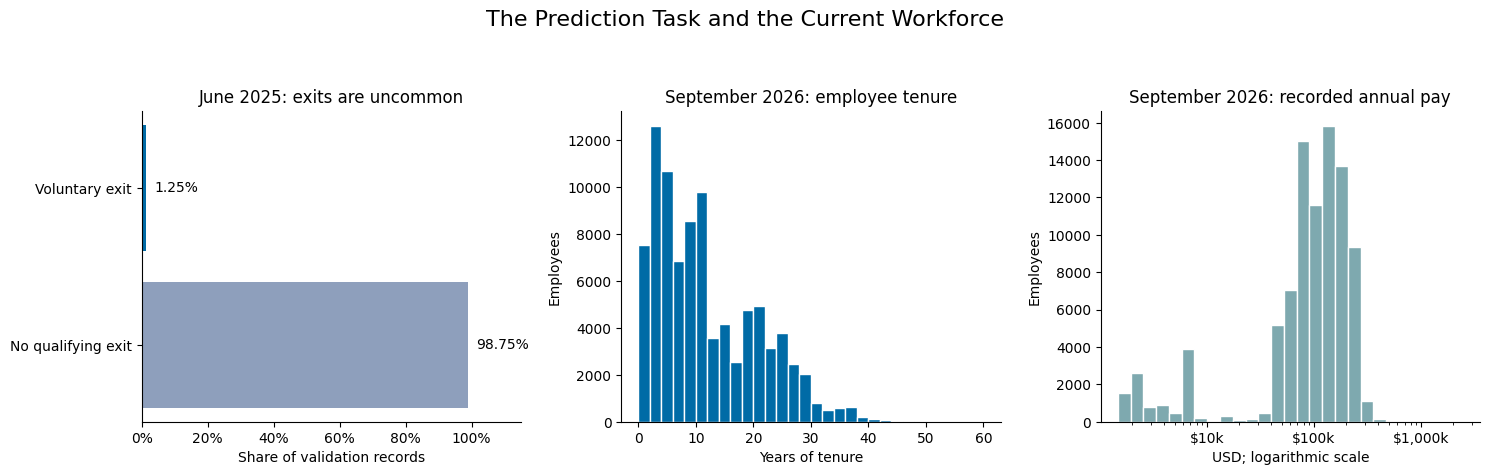

In [13]:
# Explain the rare target and show continuous inputs in the current workforce.
# The panels have different, explicitly named populations.
from matplotlib.ticker import FuncFormatter, PercentFormatter

validation_baseline = baseline_summary.loc[
    baseline_summary["data_period"] == "Validation"
].iloc[0]
validation_cases = int(validation_baseline["observed_attrition_cases"])
validation_records = int(validation_baseline["records"])
data_review_snapshot = df.loc[
    df["snapshot_date"] == df["snapshot_date"].max()
]
positive_rate = validation_cases / validation_records

data_overview_fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
axes[0].barh(["No qualifying exit", "Voluntary exit"], [1-positive_rate, positive_rate],
             color=["#8E9FBC", "#006BA6"])
axes[0].set_xlim(0, 1.15)
for i, value in enumerate([1-positive_rate, positive_rate]):
    axes[0].text(value+.025, i, f"{value:.2%}", va="center")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_xlabel("Share of validation records")
axes[0].set_title("June 2025: exits are uncommon")

tenure_years = data_review_snapshot["tenure_months"].dropna() / 12
axes[1].hist(tenure_years, bins=30, color="#006BA6", edgecolor="white")
axes[1].set_title("September 2026: employee tenure")
axes[1].set_xlabel("Years of tenure")
axes[1].set_ylabel("Employees")

salary = data_review_snapshot["annual_salary"].dropna()
salary = salary[salary > 0]
axes[2].hist(salary, bins=np.geomspace(salary.min(), salary.max(), 28),
             color="#7EA9AF", edgecolor="white")
axes[2].set_xscale("log")
axes[2].set_title("September 2026: recorded annual pay")
axes[2].set_xlabel("USD; logarithmic scale")
axes[2].set_ylabel("Employees")
axes[2].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x/1000:,.0f}k"))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
data_overview_fig.suptitle("The Prediction Task and the Current Workforce", fontsize=16)
data_overview_fig.tight_layout(rect=[0, 0, 1, .92])
plt.show()

## 6. Preparing Inputs Without Learning from Later Data

I use a **pipeline**, a repeatable sequence of preparation and modeling steps. Numeric missing values are filled with training medians, and inputs are scaled where the modeling approach uses that preparation. When I test categorical fields, I fill missing categories and convert them to indicator columns.

The pipeline learns these steps from the training portion of each check and applies them to the later records. This keeps the comparison fair and ensures the same preparation can be used when scoring a new workforce snapshot.

In [14]:
# Learn preparation from training records and reuse it on later snapshots.
def build_preprocess(num_feature_list, cat_feature_list=None):
    cat_feature_list = cat_feature_list or []

    transformers = [
        ("num", Pipeline([
            ("fill_missing", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_feature_list),
    ]

    if len(cat_feature_list) > 0:
        transformers.append((
            "cat",
            Pipeline([
                ("fill_missing", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
            ]),
            cat_feature_list,
        ))

    return ColumnTransformer(transformers)


num_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
])

full_preprocess = build_preprocess(num_features, cat_features)
numeric_only_preprocess = build_preprocess(num_features, [])

# Finalize the preparation pipeline after testing whether categories add useful value.
preprocess = full_preprocess

print("Preprocessing builders ready.")
print("Numeric features:", num_features)
print("Candidate categorical features:", cat_features)

Preprocessing builders ready.
Numeric features: ['annual_salary', 'compa_ratio', 'performance_rating', 'tenure_months', 'low_performer', 'mgr_team_size', 'mgr_avg_team_tenure', 'mgr_low_perf_pct', 'mgr_attrition_6mo_rate', 'mgr_attrition_12mo_rate', 'underpaid_flag', 'high_mgr_attrition', 'compa_tenure_interaction']
Candidate categorical features: ['region', 'entity', 'service_area_new']


## 7. Deciding Which Inputs to Keep

More inputs do not automatically make a better model. I test feature choices using two earlier calendar checks inside the training period. That leaves the main June 2025 validation snapshot for the final model and cutoff decision, rather than repeatedly using it to revise the inputs.

I look for a measurable gain in development average precision before accepting a more complicated feature set. The following sections show what I tested and what the evidence supported.

### 7.1 Testing Choices on Two Earlier Forecast Dates

The available training history supports two fixed development checks separated by about six months. For each one, I train on earlier records whose outcome windows finish before the check date, then evaluate on the later snapshot.

I use these checks to compare inputs and **hyperparameters**, the model settings chosen before the final fit. Neither the main validation snapshot nor the historical holdout chooses those development settings. Two checks provide useful evidence, but only a limited view of changing calendar conditions.

In [15]:
from sklearn.preprocessing import MinMaxScaler


def build_fixed_snapshot_cv(
    snapshot_dates,
    outcome_window_months=6,
    snapshot_spacing_months=6,
    n_snapshots=2,
):
    """Create simple calendar checks using only completed earlier outcomes."""
    snapshot_dates = pd.Series(snapshot_dates).reset_index(drop=True)
    unique_dates = [
        pd.Timestamp(date)
        for date in sorted(snapshot_dates.dropna().unique())
    ]

    latest_snapshot = unique_dates[-1]
    validation_dates = []
    for offset in reversed(range(n_snapshots)):
        target_date = shift_month_end(
            latest_snapshot, -offset * snapshot_spacing_months
        )
        eligible_dates = [date for date in unique_dates if date <= target_date]
        if eligible_dates:
            validation_date = max(eligible_dates)
            if validation_date not in validation_dates:
                validation_dates.append(validation_date)

    folds = []
    summaries = []
    for validation_date in validation_dates:
        eligible_train_dates = [
            date
            for date in unique_dates
            if shift_month_end(date, outcome_window_months) < validation_date
        ]
        if not eligible_train_dates:
            continue

        train_idx = np.flatnonzero(
            snapshot_dates.isin(eligible_train_dates).to_numpy()
        )
        valid_idx = np.flatnonzero(
            (snapshot_dates == validation_date).to_numpy()
        )
        if len(train_idx) == 0 or len(valid_idx) == 0:
            continue

        train_end = max(eligible_train_dates)
        outcome_end = shift_month_end(train_end, outcome_window_months)
        if outcome_end >= validation_date:
            raise ValueError("A development check has overlapping outcome periods.")

        folds.append((train_idx, valid_idx))
        summaries.append({
            "validation_date": validation_date,
            "train_start": min(eligible_train_dates),
            "train_end": train_end,
            "train_outcome_end": outcome_end,
            "train_rows": len(train_idx),
            "validation_rows": len(valid_idx),
        })

    if len(folds) < 2:
        raise ValueError("At least two fixed calendar checks are required.")
    return folds, pd.DataFrame(summaries)


# Use the two non-overlapping development checks supported by the available history.
temporal_cv, tuning_snapshot_summary = build_fixed_snapshot_cv(
    train_snapshot_dates,
    outcome_window_months=OUTCOME_WINDOW_MONTHS,
    snapshot_spacing_months=6,
    n_snapshots=2,
)

# Prepare a training-only matrix for the later VIF diagnostic and readable ranking table.
train_numeric = X_train[num_features].copy()
diagnostic_medians = train_numeric.median(numeric_only=True)
train_numeric_filled = train_numeric.fillna(diagnostic_medians)
minmax_scaler = MinMaxScaler(feature_range=(0, 1))
rescaled_train = pd.DataFrame(
    minmax_scaler.fit_transform(train_numeric_filled),
    columns=num_features,
    index=X_train.index,
)

print("Fixed training-period forecast checks:")
display(tuning_snapshot_summary)
print("Development checks available:", len(temporal_cv))
print("Outcome-window overlap check: PASSED")
print("Training numeric diagnostic matrix:", rescaled_train.shape)


Fixed training-period forecast checks:


,validation_date,train_start,train_end,train_outcome_end,train_rows,validation_rows
0,2024-05-31,2023-10-31,2023-10-31,2024-04-30,89706,90858
1,2024-11-30,2023-10-31,2024-04-30,2024-10-31,631039,91559


Development checks available: 2
Outcome-window overlap check: PASSED
Training numeric diagnostic matrix: (1272081, 13)


### 7.2 Testing Smaller Numeric Feature Sets

I use chi-square scores on nonnegative scaled inputs only as a screening heuristic, then compare concrete feature lists with the calendar checks. These continuous inputs do not support interpreting the selector's p-values as a valid categorical significance test, so I omit those p-values from the report.

I compare requested sets of 5, 8, 10 and all 13 inputs. If an interaction is retained, I also keep its original inputs. Development average precision, rather than a screening score or a significance claim, determines which list is retained.

In [16]:
from sklearn.feature_selection import SelectKBest, chi2


def preserve_interaction_hierarchy(feature_list):
    """Keep both original inputs when their interaction is retained."""
    selected = list(feature_list)
    if "compa_tenure_interaction" in selected:
        selected.extend(["compa_ratio", "tenure_months"])
    selected_set = set(selected)
    return [feature for feature in num_features if feature in selected_set]


# Fit feature preparation and selection separately inside every calendar check.
feature_selection_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("nonnegative_scale", MinMaxScaler(feature_range=(0, 1))),
    ("selector", SelectKBest(score_func=chi2)),
    ("clf", LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        class_weight={0: 1, 1: 5},
        random_state=RANDOM_STATE,
    )),
])

requested_k_values = [5, 8, 10, len(num_features)]
feature_k_search = GridSearchCV(
    feature_selection_pipeline,
    param_grid={"selector__k": requested_k_values},
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    return_train_score=True,
)
feature_k_search.fit(X_train[num_features], y_train)

feature_k_results = pd.DataFrame(feature_k_search.cv_results_)
feature_k_search_df = pd.DataFrame({
    "requested_k": feature_k_results["param_selector__k"].astype(int),
    "cv_train_average_precision": feature_k_results["mean_train_score"],
    "cv_average_precision": feature_k_results["mean_test_score"],
    "cv_average_precision_std": feature_k_results["std_test_score"],
    "rank": feature_k_results["rank_test_score"].astype(int),
}).sort_values("rank").reset_index(drop=True)

best_k = int(feature_k_search.best_params_["selector__k"])
selected_mask = feature_k_search.best_estimator_.named_steps[
    "selector"
].get_support()
automated_features = [
    feature for feature, keep in zip(num_features, selected_mask) if keep
]
automated_features = preserve_interaction_hierarchy(automated_features)

# Produce a readable full-training ranking without using validation or test data.
chi2_selector = SelectKBest(score_func=chi2, k="all")
chi2_selector.fit(rescaled_train, y_train)
feature_scores = (
    pd.DataFrame({
        "feature": num_features,
        "chi2_score": chi2_selector.scores_,
        "p_value": chi2_selector.pvalues_,
    })
    .sort_values("chi2_score", ascending=False)
    .reset_index(drop=True)
)


def evaluate_numeric_feature_set(feature_set_name, feature_list):
    """Measure one concrete feature list across the training-period checks."""
    feature_list = list(feature_list)
    reference_pipeline = Pipeline([
        ("preprocess", build_preprocess(feature_list, [])),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=1000,
            class_weight={0: 1, 1: 5},
            random_state=RANDOM_STATE,
        )),
    ])
    scores = cross_validate(
        reference_pipeline,
        X_train[feature_list],
        y_train,
        scoring="average_precision",
        cv=temporal_cv,
        n_jobs=1,
        return_train_score=True,
    )
    mean_train_ap = float(np.mean(scores["train_score"]))
    mean_check_ap = float(np.mean(scores["test_score"]))
    return {
        "feature_set": feature_set_name,
        "feature_count": len(feature_list),
        "features": feature_list,
        "cv_train_average_precision": mean_train_ap,
        "development_average_precision": mean_check_ap,
        "development_ap_std": float(np.std(scores["test_score"])),
        "overfit_gap": mean_train_ap - mean_check_ap,
    }


feature_selection_rows = [
    evaluate_numeric_feature_set(
        f"Automated top {best_k} with hierarchy",
        automated_features,
    )
]
if automated_features != num_features:
    feature_selection_rows.append(
        evaluate_numeric_feature_set("All numeric candidates", num_features)
    )

feature_selection_comparison_df = (
    pd.DataFrame(feature_selection_rows)
    .sort_values("development_average_precision", ascending=False)
    .reset_index(drop=True)
)

all_numeric_matches = feature_selection_comparison_df.loc[
    feature_selection_comparison_df["feature_set"] == "All numeric candidates"
]
if all_numeric_matches.empty:
    all_numeric_row = feature_selection_comparison_df.iloc[0]
else:
    all_numeric_row = all_numeric_matches.iloc[0]
best_numeric_row = feature_selection_comparison_df.iloc[0]

minimum_numeric_ap_gain = 0.001
numeric_subset_ap_gain = (
    best_numeric_row["development_average_precision"]
    - all_numeric_row["development_average_precision"]
)

if (
    best_numeric_row["feature_set"] != "All numeric candidates"
    and numeric_subset_ap_gain >= minimum_numeric_ap_gain
):
    signal_selected_num_features = list(best_numeric_row["features"])
    signal_selection_reason = (
        f"retained {best_numeric_row['feature_set']} because mean development AP "
        f"improved by {numeric_subset_ap_gain:.4f}"
    )
else:
    signal_selected_num_features = num_features.copy()
    signal_selection_reason = (
        "retained all numeric candidates because the concrete subset did not "
        f"improve mean development AP by at least {minimum_numeric_ap_gain:.4f}"
    )

print("Automated feature-count search using training-period checks:")
display(feature_k_search_df.round(5))
print("Training-only chi-square ranking:")
display(feature_scores.drop(columns="p_value"))
print("Concrete feature-list confirmation:")
display(feature_selection_comparison_df.drop(columns="features").round(5))
print("Feature decision:", signal_selection_reason)
print("Features after signal check:", signal_selected_num_features)


Automated feature-count search using training-period checks:


,requested_k,cv_train_average_precision,cv_average_precision,cv_average_precision_std,rank
0,13,0.06621,0.04361,0.00379,1
1,10,0.06679,0.04323,0.00501,2
2,8,0.06455,0.03924,0.00080,3
3,5,0.05590,0.03727,0.00605,4


Training-only chi-square ranking:


,feature,chi2_score
0,tenure_months,927.295888
1,underpaid_flag,709.061780
2,low_performer,398.515337
3,high_mgr_attrition,372.303899
4,compa_tenure_interaction,304.200602
5,mgr_attrition_12mo_rate,239.720759
6,mgr_attrition_6mo_rate,122.106205
7,annual_salary,110.199679
8,mgr_avg_team_tenure,102.275872
9,performance_rating,32.024418


Concrete feature-list confirmation:


,feature_set,feature_count,cv_train_average_precision,development_average_precision,development_ap_std,overfit_gap
0,Automated top 13 with hierarchy,13,0.06706,0.04544,0.00547,0.02161


Feature decision: retained all numeric candidates because the concrete subset did not improve mean development AP by at least 0.0010
Features after signal check: ['annual_salary', 'compa_ratio', 'performance_rating', 'tenure_months', 'low_performer', 'mgr_team_size', 'mgr_avg_team_tenure', 'mgr_low_perf_pct', 'mgr_attrition_6mo_rate', 'mgr_attrition_12mo_rate', 'underpaid_flag', 'high_mgr_attrition', 'compa_tenure_interaction']


The search favors **all 13 numeric candidates**. The smaller-list comparison does not provide the required AP improvement, so I keep the full set. The minimum required gain is 0.001 AP, or 0.1 percentage point.

### 7.3 Checking Whether Inputs Overlap Too Much

I also use **variance inflation factor (VIF)** to identify linear overlap between inputs. A high VIF is a reason to investigate, especially when interpreting coefficients; it is not a reason to assume an input has no predictive value.

I test the proposed removals on the same development checks. None improves AP by the required amount, so I retain the selected inputs. Their individual weights should be read in the context of the other fields, particularly the pay-tenure interaction.

In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


# Estimate VIF on a repeatable training sample to keep the diagnostic efficient.
vif_sample = rescaled_train[signal_selected_num_features].sample(
    n=min(200_000, len(rescaled_train)),
    random_state=RANDOM_STATE,
)
vif_with_intercept = np.column_stack([
    np.ones(len(vif_sample)),
    vif_sample.to_numpy(),
])

vif_data = pd.DataFrame({
    "feature": signal_selected_num_features,
    "vif": [
        variance_inflation_factor(vif_with_intercept, index + 1)
        for index in range(len(signal_selected_num_features))
    ],
}).sort_values("vif", ascending=False).reset_index(drop=True)

signal_feature_key = tuple(signal_selected_num_features)
signal_development_row = feature_selection_comparison_df.loc[
    feature_selection_comparison_df["features"].map(tuple) == signal_feature_key
].iloc[0]
signal_development_ap = signal_development_row["development_average_precision"]

vif_validation_rows = [{
    "feature_set": "Signal-selected baseline",
    "removed_feature": None,
    "feature_count": len(signal_selected_num_features),
    "development_average_precision": signal_development_ap,
    "features": signal_selected_num_features,
}]

high_vif_features = vif_data.loc[vif_data["vif"] > 10, "feature"].tolist()
protected_main_effects = {"compa_ratio", "tenure_months"}
removal_candidates = [
    feature for feature in high_vif_features
    if feature not in protected_main_effects
]

if (
    "compa_tenure_interaction" in signal_selected_num_features
    and vif_data["vif"].max() > 10
    and "compa_tenure_interaction" not in removal_candidates
):
    removal_candidates.append("compa_tenure_interaction")

for feature_to_remove in removal_candidates[:3]:
    reduced_features = [
        feature for feature in signal_selected_num_features
        if feature != feature_to_remove
    ]
    reduced_result = evaluate_numeric_feature_set(
        f"Remove {feature_to_remove}",
        reduced_features,
    )
    vif_validation_rows.append({
        "feature_set": reduced_result["feature_set"],
        "removed_feature": feature_to_remove,
        "feature_count": reduced_result["feature_count"],
        "development_average_precision": reduced_result[
            "development_average_precision"
        ],
        "features": reduced_features,
    })

vif_validation_df = (
    pd.DataFrame(vif_validation_rows)
    .sort_values("development_average_precision", ascending=False)
    .reset_index(drop=True)
)

best_vif_row = vif_validation_df.iloc[0]
minimum_vif_ap_gain = 0.001
vif_ap_gain = (
    best_vif_row["development_average_precision"] - signal_development_ap
)

if (
    best_vif_row["feature_set"] != "Signal-selected baseline"
    and vif_ap_gain >= minimum_vif_ap_gain
):
    selected_num_features = list(best_vif_row["features"])
    overlap_selection_reason = (
        f"removed {best_vif_row['removed_feature']} because mean development AP "
        f"improved by {vif_ap_gain:.4f}"
    )
else:
    selected_num_features = signal_selected_num_features.copy()
    overlap_selection_reason = (
        "retained the signal-selected features because no VIF-triggered removal "
        f"improved mean development AP by at least {minimum_vif_ap_gain:.4f}"
    )

numeric_feature_set_name = (
    "All candidate numeric features"
    if selected_num_features == num_features
    else "Training-validated numeric subset"
)

print("Training-sample VIF diagnostic:")
display(vif_data.round(3))
print("Training-period check for VIF-triggered removals:")
display(vif_validation_df.drop(columns="features").round(5))
print("Overlap decision:", overlap_selection_reason)
print("Numeric features carried forward:", selected_num_features)


Training-sample VIF diagnostic:


,feature,vif
0,compa_tenure_interaction,50.411
1,tenure_months,47.842
2,compa_ratio,2.360
3,underpaid_flag,1.957
4,mgr_attrition_12mo_rate,1.921
5,high_mgr_attrition,1.794
6,mgr_avg_team_tenure,1.284
7,mgr_attrition_6mo_rate,1.251
8,annual_salary,1.142
9,mgr_team_size,1.131


Training-period check for VIF-triggered removals:


,feature_set,removed_feature,feature_count,development_average_precision
0,Signal-selected baseline,None,13,0.04544
1,Remove compa_tenure_interaction,compa_tenure_interaction,12,0.03956


Overlap decision: retained the signal-selected features because no VIF-triggered removal improved mean development AP by at least 0.0010
Numeric features carried forward: ['annual_salary', 'compa_ratio', 'performance_rating', 'tenure_months', 'low_performer', 'mgr_team_size', 'mgr_avg_team_tenure', 'mgr_low_perf_pct', 'mgr_attrition_6mo_rate', 'mgr_attrition_12mo_rate', 'underpaid_flag', 'high_mgr_attrition', 'compa_tenure_interaction']


### 7.4 Asking Whether Organization Categories Add Value

I test region, entity and service area alongside the numeric inputs. Adding them changes mean development AP by **-0.03 percentage point**, below the required gain of 0.1 point. I leave them out of the final model rather than add complexity without a supported improvement.

These categories still help describe and review results. Their business context matters even when they are excluded as predictors.

In [18]:
selected_numeric_preprocess = build_preprocess(selected_num_features, [])
selected_with_categories = selected_num_features + cat_features
selected_full_preprocess = build_preprocess(selected_num_features, cat_features)

cat_development_configs = [
    ("Selected numeric", selected_num_features, selected_numeric_preprocess),
    (
        "Selected numeric + categorical",
        selected_with_categories,
        selected_full_preprocess,
    ),
]

cat_development_results = []
for name, feature_set, transformer in cat_development_configs:
    diagnostic_pipeline = Pipeline([
        ("preprocess", transformer),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=1000,
            class_weight={0: 1, 1: 5},
            random_state=RANDOM_STATE,
        )),
    ])
    scores = cross_validate(
        diagnostic_pipeline,
        X_train[feature_set],
        y_train,
        scoring="average_precision",
        cv=temporal_cv,
        n_jobs=1,
        return_train_score=True,
    )
    mean_train_ap = float(np.mean(scores["train_score"]))
    mean_check_ap = float(np.mean(scores["test_score"]))
    cat_development_results.append({
        "feature_set": name,
        "feature_count": len(feature_set),
        "cv_train_average_precision": mean_train_ap,
        "cv_average_precision": mean_check_ap,
        "cv_average_precision_std": float(np.std(scores["test_score"])),
        "overfit_gap": mean_train_ap - mean_check_ap,
    })

# Keep the established output name while making clear that the decision uses development checks.
cat_validation_df = pd.DataFrame(cat_development_results)
display(cat_validation_df.round(5))

numeric_ap = cat_validation_df.loc[
    cat_validation_df["feature_set"] == "Selected numeric",
    "cv_average_precision",
].iloc[0]
full_ap = cat_validation_df.loc[
    cat_validation_df["feature_set"] == "Selected numeric + categorical",
    "cv_average_precision",
].iloc[0]

categorical_ap_gain = full_ap - numeric_ap
minimum_categorical_ap_gain = 0.001
categorical_features_improve = categorical_ap_gain >= minimum_categorical_ap_gain

final_num_features = selected_num_features.copy()
if categorical_features_improve:
    final_cat_features = cat_features.copy()
    final_feature_set_name = numeric_feature_set_name + " + categorical"
else:
    final_cat_features = []
    final_feature_set_name = numeric_feature_set_name

final_model_features = final_num_features + final_cat_features
final_preprocess = build_preprocess(final_num_features, final_cat_features)

# Compare the modeling approaches using the same selected inputs.
selected_model_features = final_model_features
selected_preprocess = final_preprocess
preprocess = final_preprocess

print(f"Development AP gain from categorical features: {categorical_ap_gain:.4f}")
print(f"Minimum AP gain required: {minimum_categorical_ap_gain:.4f}")
if categorical_features_improve:
    print("Decision: retain categorical features in the final modeling pipeline.")
else:
    print(
        "Decision: exclude categorical features because the development AP gain "
        "did not justify the added complexity."
    )
print("Final feature set:", final_feature_set_name)
print("Final model features:", final_model_features)


,feature_set,feature_count,cv_train_average_precision,cv_average_precision,cv_average_precision_std,overfit_gap
0,Selected numeric,13,0.06706,0.04544,0.00547,0.02161
1,Selected numeric + categorical,16,0.07047,0.04514,0.00559,0.02533


Development AP gain from categorical features: -0.0003
Minimum AP gain required: 0.0010
Decision: exclude categorical features because the development AP gain did not justify the added complexity.
Final feature set: All candidate numeric features
Final model features: ['annual_salary', 'compa_ratio', 'performance_rating', 'tenure_months', 'low_performer', 'mgr_team_size', 'mgr_avg_team_tenure', 'mgr_low_perf_pct', 'mgr_attrition_6mo_rate', 'mgr_attrition_12mo_rate', 'underpaid_flag', 'high_mgr_attrition', 'compa_tenure_interaction']


### 7.5 Using the Same Inputs for Each Model

The final set has **13 numeric inputs and 0 categorical inputs**. I give all three models this same training-selected set so that the comparison reflects their modeling approaches rather than different predictor lists. The table below records the fields actually used.

In [19]:
# Display the final feature list so the selection is easy to review.
feature_summary = pd.DataFrame({
    "feature": final_model_features,
    "type": ["numeric"] * len(final_num_features) + ["categorical"] * len(final_cat_features),
})

print(f"Number of numeric features: {len(final_num_features)}")
print(f"Number of categorical features retained: {len(final_cat_features)}")
print(f"Total final model features: {len(final_model_features)}")
print("Final feature set decision:", final_feature_set_name)

display(feature_summary)

missing_features = [col for col in final_model_features if col not in X_train.columns]
if missing_features:
    raise ValueError(f"Missing final features: {missing_features}")
else:
    print("All final features are present in train, validation, and test matrices.")

Number of numeric features: 13
Number of categorical features retained: 0
Total final model features: 13
Final feature set decision: All candidate numeric features


,feature,type
0,annual_salary,numeric
1,compa_ratio,numeric
2,performance_rating,numeric
3,tenure_months,numeric
4,low_performer,numeric
5,mgr_team_size,numeric
6,mgr_avg_team_tenure,numeric
7,mgr_low_perf_pct,numeric
8,mgr_attrition_6mo_rate,numeric
9,mgr_attrition_12mo_rate,numeric


All final features are present in train, validation, and test matrices.


## 8. Starting with Logistic Regression

Logistic Regression combines the inputs into a score using fitted weights. It gives me a relatively straightforward starting model whose weights can be inspected. I test **regularization**, which limits overly large weights, along with several ways to address the rare positive outcome.

Class weighting gives more emphasis to exit cases during fitting. Under-sampling temporarily reduces the number of no-exit records in the training data. I compare these approaches, L1 and L2 penalties, and regularization strength using development AP. The later evaluation snapshots retain their actual outcome balance, so workload and precision reflect the population being reviewed.

In [20]:
from sklearn.exceptions import ConvergenceWarning

# Verify that every tuning fit and the selected refit finish optimization.
# Stop for investigation if the convergence check fails.
lr_convergence_records = []


class ConvergenceCheckedLogisticRegression(LogisticRegression):
    def fit(self, X, y, sample_weight=None):
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            super().fit(X, y, sample_weight=sample_weight)
        convergence_warnings = [
            item for item in fit_warnings
            if issubclass(item.category, ConvergenceWarning)
        ]
        iterations = int(np.max(self.n_iter_))
        lr_convergence_records.append({
            "training_rows": len(y), "C": self.C, "penalty": self.penalty,
            "solver": self.solver,
            "class_weight": str(self.class_weight), "iterations": iterations,
            "iteration_limit": self.max_iter,
            "converged": not convergence_warnings and iterations < self.max_iter,
        })
        for item in fit_warnings:
            if not issubclass(item.category, ConvergenceWarning):
                warnings.warn(str(item.message), item.category)
        if convergence_warnings or iterations >= self.max_iter:
            raise RuntimeError(
                "Logistic Regression did not converge; increase the iteration "
                "budget and rerun development checks before comparing models."
            )
        return self


from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler


# Change the fitting sample only; evaluate on the actual outcome balance.
lr_pipeline = ImbPipeline([
    ("preprocess", final_preprocess),
    ("sampler", "passthrough"),
    ("clf", ConvergenceCheckedLogisticRegression(
        solver="saga",
        max_iter=5000,
        tol=1e-3,
        random_state=RANDOM_STATE,
    )),
])

# Test a focused set of imbalance and regularization choices.
lr_param_grid = []
for class_weight in [{0: 1, 1: 3}, {0: 1, 1: 5}, "balanced"]:
    for c_value in [0.1, 1.0]:
        lr_param_grid.append({
            "sampler": ["passthrough"],
            "clf__class_weight": [class_weight],
            # A balanced-weight SAGA fit still reached the 5,000-iteration limit.
            # Use the L2-compatible LBFGS solver for those candidates only.
            "clf__solver": ["lbfgs" if class_weight == "balanced" else "saga"],
            "clf__C": [c_value],
            "clf__penalty": ["l2"],
        })

for c_value in [0.01, 10.0]:
    lr_param_grid.append({
        "sampler": ["passthrough"],
        "clf__class_weight": [{0: 1, 1: 5}],
        "clf__C": [c_value],
        "clf__penalty": ["l2"],
    })

for c_value in [0.1, 1.0]:
    lr_param_grid.append({
        "sampler": ["passthrough"],
        "clf__class_weight": [{0: 1, 1: 5}],
        "clf__C": [c_value],
        "clf__penalty": ["l1"],
    })

for sampling_ratio in [0.05, 0.10, 0.20]:
    lr_param_grid.append({
        "sampler": [RandomUnderSampler(
            sampling_strategy=sampling_ratio,
            random_state=RANDOM_STATE,
        )],
        "clf__class_weight": [None],
        "clf__C": [1.0],
        "clf__penalty": ["l2"],
    })

lr_param_grid.append({
    "sampler": [RandomUnderSampler(
        sampling_strategy=0.10,
        random_state=RANDOM_STATE,
    )],
    "clf__class_weight": [None],
    "clf__C": [0.1],
    "clf__penalty": ["l2"],
})

lr_search = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    verbose=1,
    return_train_score=True,
    error_score="raise",
)
lr_search.fit(X_train[final_model_features], y_train)

lr_model = lr_search.best_estimator_
lr_model_features = final_model_features


def describe_sampler(value):
    if value == "passthrough":
        return "No resampling"
    ratio = float(value.sampling_strategy)
    return f"Random under-sampling (1:{1 / ratio:.0f})"


def describe_class_weight(value):
    if value is None:
        return "None"
    if value == "balanced":
        return "Balanced"
    return f"{value[1]:g}:1"


lr_cv_results = pd.DataFrame(lr_search.cv_results_)
lr_imbalance_comparison_df = pd.DataFrame({
    "imbalance_strategy": lr_cv_results["param_sampler"].map(describe_sampler),
    "class_weight": lr_cv_results["param_clf__class_weight"].map(
        describe_class_weight
    ),
    "C": lr_cv_results["param_clf__C"].astype(float),
    "penalty": lr_cv_results["param_clf__penalty"].astype(str),
    "solver": lr_cv_results["params"].map(lambda p: p.get("clf__solver", "saga")),
    "cv_train_average_precision": lr_cv_results["mean_train_score"],
    "cv_average_precision": lr_cv_results["mean_test_score"],
    "cv_overfit_gap": (
        lr_cv_results["mean_train_score"] - lr_cv_results["mean_test_score"]
    ),
    "cv_average_precision_std": lr_cv_results["std_test_score"],
    "rank": lr_cv_results["rank_test_score"].astype(int),
}).sort_values(["rank", "imbalance_strategy", "C", "penalty"]).reset_index(drop=True)

baseline_mask = (
    (lr_imbalance_comparison_df["imbalance_strategy"] == "No resampling")
    & (lr_imbalance_comparison_df["class_weight"] == "5:1")
    & (lr_imbalance_comparison_df["C"] == 1.0)
    & (lr_imbalance_comparison_df["penalty"] == "l2")
)
baseline_ap = lr_imbalance_comparison_df.loc[
    baseline_mask, "cv_average_precision"
].iloc[0]
imbalance_tuning_ap_gain = lr_search.best_score_ - baseline_ap

best_sampler = describe_sampler(lr_search.best_params_["sampler"])
best_class_weight = describe_class_weight(
    lr_search.best_params_["clf__class_weight"]
)
lr_cv_train_ap = float(
    lr_search.cv_results_["mean_train_score"][lr_search.best_index_]
)
lr_cv_validation_ap = float(lr_search.best_score_)
lr_cv_overfit_gap = lr_cv_train_ap - lr_cv_validation_ap

display(lr_imbalance_comparison_df.round(5))
print("Logistic Regression feature set:", final_feature_set_name)
print("Selected imbalance strategy:", best_sampler)
print("Selected class weight:", best_class_weight)
print("Selected C:", lr_search.best_params_["clf__C"])
print("Selected penalty:", lr_search.best_params_["clf__penalty"])
print("Best development average precision:", round(lr_search.best_score_, 6))
print("Reference 5:1, C=1.0, L2 average precision:", round(baseline_ap, 6))
print("Average-precision gain from tuning:", round(imbalance_tuning_ap_gain, 6))
print("Selected training average precision:", round(lr_cv_train_ap, 6))
print("Selected overfitting gap:", round(lr_cv_overfit_gap, 6))


lr_convergence_audit = pd.DataFrame(lr_convergence_records)
if not lr_convergence_audit["converged"].all():
    raise RuntimeError("Not all Logistic Regression fits passed convergence verification.")
print("Convergence verified for candidate-fold and selected refit:", len(lr_convergence_audit), "fits")
print("Largest iteration count:", int(lr_convergence_audit["iterations"].max()))
print("Iteration budget:", lr_model.named_steps["clf"].max_iter)
print("Selected full-training iterations:", int(np.max(lr_model.named_steps["clf"].n_iter_)))

print("Selected solver:", lr_model.named_steps["clf"].solver)

print("Convergence audit by solver and penalty:")
display(lr_convergence_audit.groupby(["solver", "penalty"]).agg(
    fits=("converged", "size"),
    max_iterations=("iterations", "max"),
    all_converged=("converged", "all"),
))


Fitting 2 folds for each of 14 candidates, totalling 28 fits


,imbalance_strategy,class_weight,C,penalty,solver,cv_train_average_precision,cv_average_precision,cv_overfit_gap,cv_average_precision_std,rank
0,No resampling,5:1,1.00,l1,saga,0.06707,0.04539,0.02168,0.00542,1
1,No resampling,5:1,1.00,l2,saga,0.06706,0.04538,0.02167,0.00541,2
2,No resampling,5:1,0.10,l1,saga,0.06705,0.04538,0.02167,0.00540,3
3,No resampling,5:1,10.00,l2,saga,0.06707,0.04538,0.02169,0.00545,4
4,No resampling,5:1,0.10,l2,saga,0.06714,0.04529,0.02185,0.00531,5
5,No resampling,3:1,1.00,l2,saga,0.06787,0.04527,0.02260,0.00524,6
6,Random under-sampling (1:10),None,1.00,l2,saga,0.06653,0.04526,0.02128,0.00535,7
7,Random under-sampling (1:20),None,1.00,l2,saga,0.06767,0.04507,0.02260,0.00509,8
8,No resampling,3:1,0.10,l2,saga,0.06776,0.04504,0.02272,0.00507,9
9,Random under-sampling (1:5),None,1.00,l2,saga,0.06482,0.04499,0.01983,0.00512,10


Logistic Regression feature set: All candidate numeric features
Selected imbalance strategy: No resampling
Selected class weight: 5:1
Selected C: 1.0
Selected penalty: l1
Best development average precision: 0.045393
Reference 5:1, C=1.0, L2 average precision: 0.045382
Average-precision gain from tuning: 1.1e-05
Selected training average precision: 0.067071
Selected overfitting gap: 0.021678
Convergence verified for candidate-fold and selected refit: 29 fits
Largest iteration count: 143
Iteration budget: 5000
Selected full-training iterations: 35
Selected solver: saga
Convergence audit by solver and penalty:


fits  max_iterations  all_converged
solver penalty                                     
lbfgs  l2          4              14           True
saga   l1          5              47           True
       l2         20             143           True

The search selects **no resampling**, a **5:1 class weight**, `C=1` and L1 regularization. Giving exit cases more fitting weight helps the model learn the uncommon outcome; evaluation still uses each snapshot's actual outcome balance.

Mean development AP is **4.54%**, with a training-to-development gap of **2.17 percentage points**. The gain over the 5:1-weighted, `C=1`, L2 reference is only **0.0011 percentage point**. These nearly equal results do not establish a meaningful advantage for L1.

### Checking That the Fitting Process Finished Properly

An earlier balanced-weight SAGA fit reached its iteration limit. I use LBFGS for balanced-weight L2 candidates and SAGA for the others. These are optimization algorithms, identified in the comparison table.

All **29 fits** passed the explicit convergence check. The largest count was **143 iterations**, and the selected full-training fit used **35**, within the 5,000-iteration budget. The workflow stops if a fit warns or reaches the limit. Convergence verifies that fitting finished; later evaluation determines usefulness.

## 9. Turning a Ranking into an HR Review List

A ranking needs a cutoff before it becomes a list HR can review. I use a shared target of capturing about **25% of observed voluntary-exit cases** in validation and choose the highest qualifying cutoff. This keeps the list as focused as possible at that target.

The target is a modeling comparison assumption, not an agreed HR workload. The next table shows what happens when I ask the model to capture fewer or more cases.

In [21]:
# Find a focused list that captures at least 25% of validation exit cases.
def choose_threshold_for_recall(y_true, y_prob, target_recall=0.25):
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    threshold_rows = pd.DataFrame({
        "threshold": thresholds,
        "precision": precision[:-1],
        "recall": recall[:-1],
    })
    threshold_rows["f1"] = (
        2 * threshold_rows["precision"] * threshold_rows["recall"] /
        (threshold_rows["precision"] + threshold_rows["recall"] + 1e-12)
    )
    threshold_rows["flagged_rate"] = [
        np.mean(y_prob >= threshold)
        for threshold in threshold_rows["threshold"]
    ]

    eligible = threshold_rows.loc[
        threshold_rows["recall"] >= target_recall
    ].copy()
    if len(eligible) > 0:
        chosen = eligible.sort_values("threshold", ascending=False).iloc[0]
        decision = "target_recall_met"
    else:
        chosen = threshold_rows.sort_values("f1", ascending=False).iloc[0]
        decision = "fallback_best_f1"

    return float(chosen["threshold"]), chosen.to_dict(), threshold_rows, decision


def evaluate_at_threshold(model_name, y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    ap = average_precision_score(y_true, y_prob)
    base_rate = float(np.mean(y_true))
    precision_value = precision_score(y_true, y_pred, zero_division=0)
    recall_value = recall_score(y_true, y_pred, zero_division=0)

    return {
        "model": model_name,
        "threshold": threshold,
        "average_precision": ap,
        "roc_auc": roc_auc_score(y_true, y_prob),
        "base_rate": base_rate,
        "lift_vs_base": precision_value / base_rate if base_rate > 0 else np.nan,
        "precision": precision_value,
        "recall": recall_value,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "flagged_rate": float(np.mean(y_pred)),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
    }, y_pred


target_recall = 0.25

# Select the cutoff from validation only; the previously reviewed holdout does not set it.
lr_valid_prob = lr_model.predict_proba(X_valid[lr_model_features])[:, 1]
lr_threshold, lr_threshold_info, lr_threshold_table, lr_threshold_policy = (
    choose_threshold_for_recall(
        y_valid,
        lr_valid_prob,
        target_recall=target_recall,
    )
)
lr_valid_metrics, lr_valid_pred = evaluate_at_threshold(
    "Logistic Regression",
    y_valid,
    lr_valid_prob,
    lr_threshold,
)

print("Target recall:", target_recall)
print("Logistic Regression threshold decision:", lr_threshold_policy)
print("Chosen Logistic Regression threshold:", lr_threshold)
print("Validation threshold details:")
display(pd.DataFrame([lr_threshold_info]).round(4))


Target recall: 0.25
Logistic Regression threshold decision: target_recall_met
Chosen Logistic Regression threshold: 0.1542384045863066
Validation threshold details:


,threshold,precision,recall,f1,flagged_rate
0,0.1542,0.0472,0.2504,0.0795,0.0664


### 9.1 Connecting Cases Captured to Review Capacity

At the nominal 25% target, Logistic Regression captures **286 of 1,142 validation exit cases**, with **6,056 employees on the list** (6.6% of the workforce). The list's observed exit share is **4.7%**.

Capturing a larger share of cases requires reviewing more people. HR would need to decide which workload is feasible and how to make the review supportive and useful.

In [22]:
# Compare HR workload at three possible levels of attrition-case coverage.
capacity_targets = [0.10, target_recall, 0.50]
capacity_rows = []

for capacity_target in capacity_targets:
    threshold, details, _, _ = choose_threshold_for_recall(
        y_valid,
        lr_valid_prob,
        target_recall=capacity_target,
    )
    capacity_pred = lr_valid_prob >= threshold
    capacity_rows.append({
        "Recall target": f"{capacity_target:.0%}",
        "Validation cases captured": f"{int(((y_valid.to_numpy() == 1) & capacity_pred).sum()):,}",
        "Approx. employees flagged": f"{int(round(capacity_pred.sum(), -2)):,}",
        "Workforce flagged": f"{capacity_pred.mean():.1%}",
        "Precision": f"{details['precision']:.1%}",
    })

# Show how much the review list grows when the recall target increases.
validation_capacity_comparison = pd.DataFrame(capacity_rows)
display(validation_capacity_comparison)

,Recall target,Validation cases captured,Approx. employees flagged,Workforce flagged,Precision
0,10%,115,"2,300",2.5%,5.0%
1,25%,286,"6,100",6.6%,4.7%
2,50%,571,"17,000",18.6%,3.4%


## 10. Checking Logistic Regression on Validation

With the inputs and tuning settings chosen, I evaluate Logistic Regression on the June 2025 snapshot. I look first at ranking quality, then at the list produced by its cutoff. The curves show how results change across cutoffs; the confusion matrix shows the counts at the selected one.

The January historical holdout comes later, after the final model choice is fixed.

In [23]:
# Evaluate validation now; replay the historical holdout after selection.
print("Logistic Regression validation metrics:")
display(pd.DataFrame([lr_valid_metrics]).round(4))

print("Logistic Regression classification report on validation:")
print(classification_report(y_valid, lr_valid_pred, zero_division=0))


Logistic Regression validation metrics:


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,Logistic Regression,0.1542,0.0336,0.7208,0.0125,3.7701,0.0472,0.2504,0.0795,0.0664,286,5770,856,84255


Logistic Regression classification report on validation:
              precision    recall  f1-score   support

         0.0       0.99      0.94      0.96     90025
         1.0       0.05      0.25      0.08      1142

    accuracy                           0.93     91167
   macro avg       0.52      0.59      0.52     91167
weighted avg       0.98      0.93      0.95     91167



Logistic Regression captures **25.0%** of validation exit cases, with **4.7%** precision and **6.6%** of employees listed. AP is **3.36%**, compared with the **1.25%** untargeted baseline.

The list's exit share is **3.8 times** the workforce rate. This supports prioritization, but many listed records do not have the target outcome and most exits remain outside the list.

### 10.2 Looking at Separation Across Cutoffs

The **ROC curve** shows how capturing more exit cases also brings more no-exit records above the cutoff. ROC-AUC summarizes that separation: 0.5 is random ranking and 1.0 is perfect separation. I include it as a second view of ranking quality, alongside AP and the review-list measures.

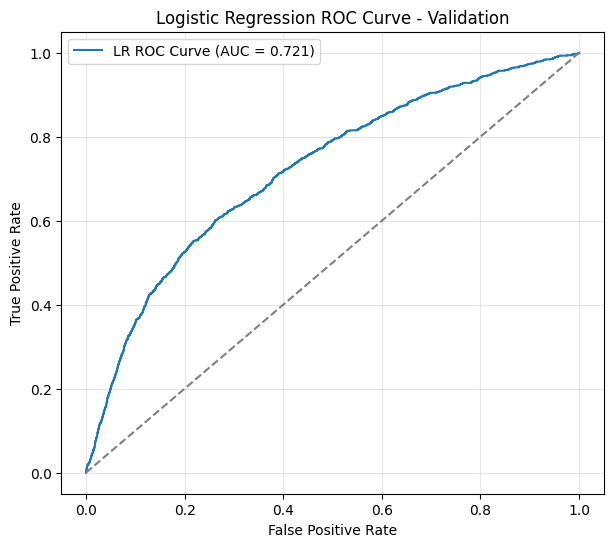

In [24]:
# Show validation ranking across all cutoffs, where 0.5 is random and 1.0 is perfect.
fpr, tpr, _ = roc_curve(y_valid, lr_valid_prob)
lr_valid_roc_auc = roc_auc_score(y_valid, lr_valid_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"LR ROC Curve (AUC = {lr_valid_roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC Curve - Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 10.3 Looking at the Tradeoff HR Would Face

The **precision-recall curve** is especially relevant when exits are rare. It shows how the list's exit share changes as the model captures more exit cases. The horizontal line is the untargeted reference, and the marked point is the cutoff selected on validation. This makes the capture-versus-workload tradeoff visible.

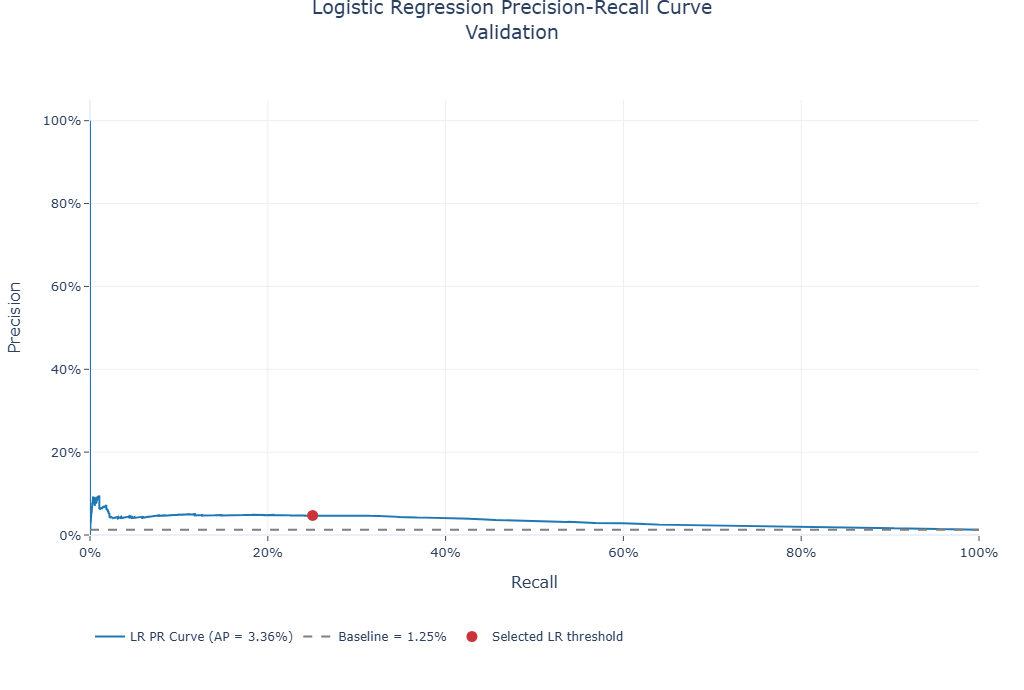

In [25]:
# Show validation precision as more attrition cases are included.
import plotly.graph_objects as go

lr_precision_curve, lr_recall_curve, _ = precision_recall_curve(
    y_valid, lr_valid_prob
)
lr_valid_ap = average_precision_score(y_valid, lr_valid_prob)
lr_validation_baseline = y_valid.mean()

lr_pr_fig = go.Figure()
lr_pr_fig.add_trace(go.Scatter(
    x=lr_recall_curve,
    y=lr_precision_curve,
    mode="lines",
    name=f"LR PR Curve (AP = {lr_valid_ap:.2%})",
    line=dict(color="#1f77b4", width=2),
    hovertemplate="Recall: %{x:.2%}<br>Precision: %{y:.2%}<extra>Logistic Regression</extra>",
))
lr_pr_fig.add_trace(go.Scatter(
    x=[0, 1],
    y=[lr_validation_baseline, lr_validation_baseline],
    mode="lines",
    name=f"Baseline = {lr_validation_baseline:.2%}",
    line=dict(color="#7f7f7f", dash="dash", width=2),
    hovertemplate="Workforce exit rate: %{y:.2%}<extra>Untargeted baseline</extra>",
))
lr_pr_fig.add_trace(go.Scatter(
    x=[lr_valid_metrics["recall"]],
    y=[lr_valid_metrics["precision"]],
    mode="markers",
    name="Selected LR threshold",
    marker=dict(color="#CB333B", size=11),
    customdata=[[lr_valid_metrics["threshold"], lr_valid_metrics["flagged_rate"]]],
    hovertemplate=(
        "Recall: %{x:.2%}<br>Precision: %{y:.2%}"
        "<br>LR cutoff: %{customdata[0]:.3f}"
        "<br>Workforce flagged: %{customdata[1]:.2%}<extra>Selected LR threshold</extra>"
    ),
))
lr_pr_fig.update_layout(
    title=dict(text="Logistic Regression Precision-Recall Curve<br>Validation",
               x=0.5, y=0.98, xanchor="center", yanchor="top", font=dict(size=19)),
    template="plotly_white",
    width=950,
    height=690,
    font=dict(size=13),
    margin=dict(l=90, r=45, t=100, b=155),
    # Keep the legend below the x-axis, away from the two-line title.
    legend=dict(orientation="h", x=0, y=-0.20, xanchor="left",
                yanchor="top", font=dict(size=12)),
    hovermode="closest",
    xaxis=dict(title="Recall", tickformat=".0%", range=[0, 1], gridcolor="#eeeeee",
               automargin=True, title_standoff=18, ticks="outside", ticklen=5),
    yaxis=dict(title="Precision", tickformat=".0%", range=[0, 1.05], gridcolor="#eeeeee",
               automargin=True, title_standoff=18, ticks="outside", ticklen=5),
)
lr_pr_fig.show()


### 10.4 Counting What the List Finds and Misses

The **confusion matrix** puts the cutoff result into four counts: exit cases on the list, no-exit records on the list, exit cases outside it, and no-exit records outside it. These are often called true positives, false positives, false negatives and true negatives.

For HR, the first three counts explain what the list finds, how much additional review it creates, and what it misses. “No exit” here means no qualifying voluntary exit within the target window.

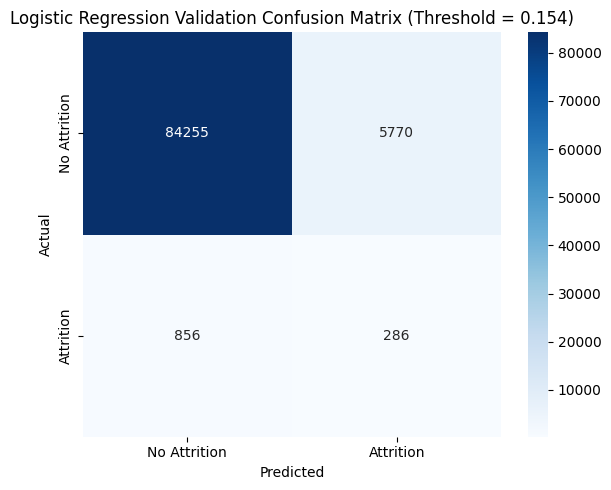

In [26]:
# Count validation cases identified, missed, and added to the review list.
cm = confusion_matrix(y_valid, lr_valid_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(
    f"Logistic Regression Validation Confusion Matrix "
    f"(Threshold = {lr_threshold:.3f})"
)
plt.tight_layout()
plt.show()


## 11. Testing a More Flexible Alternative: Random Forest

Random Forest combines many decision trees and can represent patterns that a weighted linear score may miss. I start with a flexible reference, then test shallower trees and larger leaves to reduce the chance of fitting details that do not carry forward.

I use a practical **overfitting safeguard**: the training AP should not exceed development AP by more than **five percentage points** when a qualifying candidate is available. This gap is a diagnostic, not a guarantee of future performance. If no candidate passes, I retain the one with the smallest gap for comparison and keep its limitation visible.

In [27]:
# Measure a flexible forest before testing simpler tree settings.
rf_reference_pipeline = Pipeline([
    ("preprocess", final_preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=20,
        min_samples_split=10,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf_reference_scores = cross_validate(
    rf_reference_pipeline,
    X_train[final_model_features],
    y_train,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    return_train_score=True,
)
rf_reference_train_ap = float(np.mean(rf_reference_scores["train_score"]))
rf_reference_validation_ap = float(np.mean(rf_reference_scores["test_score"]))
rf_reference_gap = rf_reference_train_ap - rf_reference_validation_ap

# Test simpler trees to reduce the training-to-development gap.
rf_pipeline = Pipeline([
    ("preprocess", final_preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf_param_dist = {
    "clf__max_depth": [6, 10, 15],
    "clf__min_samples_leaf": [50, 100, 250],
    "clf__min_samples_split": [50, 100, 250],
    "clf__max_features": ["sqrt", 0.5],
}
rf_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=6,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbose=1,
    return_train_score=True,
)
rf_search.fit(X_train[final_model_features], y_train)

# Apply the development-gap rule before choosing the forest settings.
rf_mean_train = np.asarray(rf_search.cv_results_["mean_train_score"])
rf_mean_check = np.asarray(rf_search.cv_results_["mean_test_score"])
rf_candidate_gaps = rf_mean_train - rf_mean_check
rf_gap_limit = 0.05
rf_controlled_indices = np.flatnonzero(rf_candidate_gaps <= rf_gap_limit)
if len(rf_controlled_indices) > 0:
    rf_selected_index = int(
        rf_controlled_indices[np.argmax(rf_mean_check[rf_controlled_indices])]
    )
    rf_selection_guard = "highest development AP among candidates with gap <= 0.05"
else:
    rf_selected_index = int(np.argmin(rf_candidate_gaps))
    rf_selection_guard = "smallest available overfitting gap"

rf_selected_params = rf_search.cv_results_["params"][rf_selected_index]
rf_model = clone(rf_pipeline).set_params(**rf_selected_params)
rf_model.fit(X_train[final_model_features], y_train)
rf_model_features = final_model_features
rf_search.selected_index_ = rf_selected_index
rf_cv_train_ap = float(rf_mean_train[rf_selected_index])
rf_cv_validation_ap = float(rf_mean_check[rf_selected_index])
rf_cv_overfit_gap = float(rf_candidate_gaps[rf_selected_index])

rf_overfit_action_df = pd.DataFrame({
    "version": ["Flexible reference", "Regularized search winner"],
    "training_average_precision": [rf_reference_train_ap, rf_cv_train_ap],
    "development_average_precision": [
        rf_reference_validation_ap, rf_cv_validation_ap
    ],
    "overfit_gap": [rf_reference_gap, rf_cv_overfit_gap],
})

rf_cv_results = pd.DataFrame(rf_search.cv_results_)
rf_tuning_comparison_df = pd.DataFrame({
    "max_depth": rf_cv_results["param_clf__max_depth"],
    "min_samples_leaf": rf_cv_results["param_clf__min_samples_leaf"],
    "min_samples_split": rf_cv_results["param_clf__min_samples_split"],
    "max_features": rf_cv_results["param_clf__max_features"],
    "cv_train_average_precision": rf_cv_results["mean_train_score"],
    "cv_average_precision": rf_cv_results["mean_test_score"],
    "cv_overfit_gap": (
        rf_cv_results["mean_train_score"] - rf_cv_results["mean_test_score"]
    ),
    "rank": rf_cv_results["rank_test_score"].astype(int),
    "selected": rf_cv_results.index == rf_selected_index,
}).sort_values("rank").reset_index(drop=True)

print("Random Forest overfitting response:")
display(rf_overfit_action_df.round(5))
print("Regularized Random Forest settings tested:")
display(rf_tuning_comparison_df.round(5))
print("Random Forest feature set:", final_feature_set_name)
print("Random Forest selected parameters:", rf_selected_params)
print("Random Forest selection safeguard:", rf_selection_guard)
print("Random Forest selected development AP:", round(rf_cv_validation_ap, 6))
print("Random Forest overfitting-gap reduction:", round(
    rf_reference_gap - rf_cv_overfit_gap, 6
))


Fitting 2 folds for each of 6 candidates, totalling 12 fits
Random Forest overfitting response:


,version,training_average_precision,development_average_precision,overfit_gap
0,Flexible reference,0.46376,0.05813,0.40564
1,Regularized search winner,0.11493,0.04889,0.06603


Regularized Random Forest settings tested:


,max_depth,min_samples_leaf,min_samples_split,max_features,cv_train_average_precision,cv_average_precision,cv_overfit_gap,rank,selected
0,15,100,100,0.5,0.20733,0.06001,0.14732,1,False
1,15,100,50,0.5,0.20733,0.06001,0.14732,1,False
2,15,250,250,sqrt,0.14633,0.05665,0.08967,3,False
3,10,50,100,sqrt,0.17063,0.05575,0.11489,4,False
4,6,100,50,0.5,0.12357,0.05539,0.06818,5,False
5,6,100,250,sqrt,0.11493,0.04889,0.06603,6,True


Random Forest feature set: All candidate numeric features
Random Forest selected parameters: {'clf__min_samples_split': 250, 'clf__min_samples_leaf': 100, 'clf__max_features': 'sqrt', 'clf__max_depth': 6}
Random Forest selection safeguard: smallest available overfitting gap
Random Forest selected development AP: 0.048895
Random Forest overfitting-gap reduction: 0.339603


The flexible forest has a training-to-development AP gap of **40.56 percentage points**, with development AP of **5.81%**. Restricting complexity reduces the gap to **6.60 points**, with development AP of **4.89%**.

This is a substantial reduction, but it still exceeds the five-point limit. I carry the smallest-gap configuration forward for comparison and keep it ineligible under the final selection rule.

### 11.2 Seeing the Forest's Validation Tradeoff

Random Forest captures **25.0%** of cases with **5.08%** precision, requiring **5,627 reviews** (6.2% of employees). Validation AP is **3.56%**.

Useful ranking and a more concentrated list do not override a failed development-gap safeguard.

In [28]:
# Evaluate the regularized Random Forest on validation only.
rf_valid_prob = rf_model.predict_proba(
    X_valid[rf_model_features]
)[:, 1]
rf_threshold, rf_threshold_info, rf_threshold_table, rf_threshold_rule = (
    choose_threshold_for_recall(
        y_valid,
        rf_valid_prob,
        target_recall=target_recall,
    )
)
rf_valid_metrics, rf_valid_pred = evaluate_at_threshold(
    "Random Forest",
    y_valid,
    rf_valid_prob,
    rf_threshold,
)

print("Random Forest threshold result:", rf_threshold_rule)
print("Chosen Random Forest threshold:", rf_threshold)
print("Validation threshold details:")
display(pd.DataFrame([rf_threshold_info]).round(4))
print("Random Forest validation metrics:")
display(pd.DataFrame([rf_valid_metrics]).round(4))


Random Forest threshold result: target_recall_met
Chosen Random Forest threshold: 0.699911162306823
Validation threshold details:


,threshold,precision,recall,f1,flagged_rate
0,0.6999,0.0508,0.2504,0.0845,0.0617


Random Forest validation metrics:


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,Random Forest,0.6999,0.0356,0.7474,0.0125,4.0575,0.0508,0.2504,0.0845,0.0617,286,5341,856,84684


## 12. Testing Simpler Gradient Boosting

Gradient Boosting builds small trees in sequence, with each tree addressing patterns the earlier ones missed. The previous search produced a useful validation list, but its 5.21-point development gap exceeded my five-point safeguard.

I therefore fixed a focused set of eight simpler configurations before inspecting new validation results: three or five leaves, at least 500 or 1,000 records per leaf, and stronger L2 penalties. Learning rate, iteration budget, class weights, features and calendar checks stay fixed. Fewer leaves and larger leaf groups restrict the patterns a tree can learn; regularization further limits overly specific fits.

I select the highest development AP among candidates passing the gap safeguard, then evaluate only that choice on June validation. June has already informed earlier project work, so this remains development evidence. A later untouched period is needed for independent confirmation.

**Technical qualification:** The outer development folds follow calendar order. The fitted histogram booster also uses an internal random 10% split of each earlier training fold for early stopping. This split stays inside training, but the stopping check itself is not chronological. A future experiment should compare disabled early stopping or an explicitly chronological stopping set using development data before changing the model. I do not describe this version as fully chronological at every internal step.

In [29]:
from threadpoolctl import threadpool_limits


# Prepare the complete numeric table required by the histogram-based GBM model.
gbm_transformers = [
    ("num", SimpleImputer(strategy="median"), final_num_features),
]
if len(final_cat_features) > 0:
    gbm_transformers.append((
        "cat",
        Pipeline([
            ("fill_missing", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=50,
                sparse_output=False,
            )),
        ]),
        final_cat_features,
    ))

gbm_preprocess = ColumnTransformer(gbm_transformers, sparse_threshold=0)

gbm_reference_pipeline = Pipeline([
    ("preprocess", gbm_preprocess),
    ("clf", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=31,
        min_samples_leaf=50,
        l2_regularization=1.0,
        class_weight={0: 1, 1: 5},
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    )),
])
with threadpool_limits(limits=1):
    gbm_reference_scores = cross_validate(
        gbm_reference_pipeline,
        X_train[final_model_features],
        y_train,
        scoring="average_precision",
        cv=temporal_cv,
        n_jobs=1,
        return_train_score=True,
    )
gbm_reference_train_ap = float(np.mean(gbm_reference_scores["train_score"]))
gbm_reference_validation_ap = float(np.mean(gbm_reference_scores["test_score"]))
gbm_reference_gap = gbm_reference_train_ap - gbm_reference_validation_ap

gbm_pipeline = Pipeline([
    ("preprocess", gbm_preprocess),
    ("clf", HistGradientBoostingClassifier(
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    )),
])
# Fix a small set before evaluating June validation. Only tree complexity changes.
gbm_simple_specs = [
    (3, 500, 5.0), (3, 500, 10.0), (3, 1000, 10.0), (3, 1000, 20.0),
    (5, 500, 5.0), (5, 500, 10.0), (5, 1000, 10.0), (5, 1000, 20.0),
]
gbm_param_grid = [
    {
        "clf__learning_rate": [0.05],
        "clf__max_iter": [100],
        "clf__max_leaf_nodes": [leaves],
        "clf__min_samples_leaf": [leaf_size],
        "clf__l2_regularization": [penalty],
        "clf__class_weight": ["balanced"],
    }
    for leaves, leaf_size, penalty in gbm_simple_specs
]
gbm_search = GridSearchCV(
    gbm_pipeline,
    param_grid=gbm_param_grid,
    scoring="average_precision",
    cv=temporal_cv,
    n_jobs=1,
    refit=False,
    verbose=1,
    return_train_score=True,
    error_score="raise",
)
with threadpool_limits(limits=1):
    gbm_search.fit(X_train[final_model_features], y_train)

gbm_mean_train = np.asarray(gbm_search.cv_results_["mean_train_score"])
gbm_mean_check = np.asarray(gbm_search.cv_results_["mean_test_score"])
gbm_candidate_gaps = gbm_mean_train - gbm_mean_check
gbm_gap_limit = 0.05
gbm_controlled_indices = np.flatnonzero(gbm_candidate_gaps <= gbm_gap_limit)
if len(gbm_controlled_indices) > 0:
    gbm_selected_index = int(
        gbm_controlled_indices[np.argmax(gbm_mean_check[gbm_controlled_indices])]
    )
    gbm_selection_guard = "highest development AP among candidates with gap <= 0.05"
else:
    gbm_selected_index = int(np.argmin(gbm_candidate_gaps))
    gbm_selection_guard = "smallest available overfitting gap"

gbm_selected_params = gbm_search.cv_results_["params"][gbm_selected_index]
gbm_model = clone(gbm_pipeline).set_params(**gbm_selected_params)
with threadpool_limits(limits=1):
    gbm_model.fit(X_train[final_model_features], y_train)
gbm_model_features = final_model_features
gbm_search.selected_index_ = gbm_selected_index
gbm_cv_train_ap = float(gbm_mean_train[gbm_selected_index])
gbm_cv_validation_ap = float(gbm_mean_check[gbm_selected_index])
gbm_cv_overfit_gap = float(gbm_candidate_gaps[gbm_selected_index])

gbm_overfit_action_df = pd.DataFrame({
    "version": ["Flexible reference", "Regularized search winner"],
    "training_average_precision": [gbm_reference_train_ap, gbm_cv_train_ap],
    "development_average_precision": [
        gbm_reference_validation_ap, gbm_cv_validation_ap
    ],
    "overfit_gap": [gbm_reference_gap, gbm_cv_overfit_gap],
})

gbm_cv_results = pd.DataFrame(gbm_search.cv_results_)
gbm_tuning_comparison_df = pd.DataFrame({
    "learning_rate": gbm_cv_results["param_clf__learning_rate"].astype(float),
    "max_iter": gbm_cv_results["param_clf__max_iter"].astype(int),
    "max_leaf_nodes": gbm_cv_results["param_clf__max_leaf_nodes"].astype(int),
    "min_samples_leaf": gbm_cv_results["param_clf__min_samples_leaf"].astype(int),
    "l2_regularization": gbm_cv_results[
        "param_clf__l2_regularization"
    ].astype(float),
    "class_weight": gbm_cv_results["param_clf__class_weight"].map(str),
    "cv_train_average_precision": gbm_cv_results["mean_train_score"],
    "cv_average_precision": gbm_cv_results["mean_test_score"],
    "cv_overfit_gap": (
        gbm_cv_results["mean_train_score"] - gbm_cv_results["mean_test_score"]
    ),
    "cv_average_precision_std": gbm_cv_results["std_test_score"],
    "rank": gbm_cv_results["rank_test_score"].astype(int),
    "selected": gbm_cv_results.index == gbm_selected_index,
}).sort_values("rank").reset_index(drop=True)

print("GBM overfitting response:")
display(gbm_overfit_action_df.round(5))
print("Regularized GBM settings tested:")
display(gbm_tuning_comparison_df.round(5))
print("GBM feature set:", final_feature_set_name)
print("GBM selected development AP:", round(gbm_cv_validation_ap, 6))
print("GBM selected parameters:", gbm_selected_params)
print("GBM selection safeguard:", gbm_selection_guard)
print("GBM overfitting-gap reduction:", round(
    gbm_reference_gap - gbm_cv_overfit_gap, 6
))


Fitting 2 folds for each of 8 candidates, totalling 16 fits
GBM overfitting response:


,version,training_average_precision,development_average_precision,overfit_gap
0,Flexible reference,0.20204,0.05959,0.14245
1,Regularized search winner,0.08573,0.04803,0.03770


Regularized GBM settings tested:


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,class_weight,cv_train_average_precision,cv_average_precision,cv_overfit_gap,cv_average_precision_std,rank,selected
0,0.05,100,5,1000,10.0,balanced,0.08573,0.04803,0.03770,0.00071,1,True
1,0.05,100,5,500,5.0,balanced,0.08729,0.04790,0.03939,0.00020,2,False
2,0.05,100,5,1000,20.0,balanced,0.08589,0.04765,0.03824,0.00040,3,False
3,0.05,100,5,500,10.0,balanced,0.08658,0.04729,0.03929,0.00001,4,False
4,0.05,100,3,1000,10.0,balanced,0.07394,0.04249,0.03145,0.00218,5,False
5,0.05,100,3,500,10.0,balanced,0.07424,0.04238,0.03185,0.00207,6,False
6,0.05,100,3,500,5.0,balanced,0.07403,0.04234,0.03168,0.00210,7,False
7,0.05,100,3,1000,20.0,balanced,0.07455,0.04210,0.03245,0.00238,8,False


GBM feature set: All candidate numeric features
GBM selected development AP: 0.048029
GBM selected parameters: {'clf__class_weight': 'balanced', 'clf__l2_regularization': 10.0, 'clf__learning_rate': 0.05, 'clf__max_iter': 100, 'clf__max_leaf_nodes': 5, 'clf__min_samples_leaf': 1000}
GBM selection safeguard: highest development AP among candidates with gap <= 0.05
GBM overfitting-gap reduction: 0.104749


### 12.2 What the Simpler Search Supported

The selected configuration uses a learning rate of **0.05**, up to **100 trees**, **5 leaves per tree**, at least **1,000 records per leaf**, and L2 regularization of **10**, with balanced class weights.

Mean development AP is **4.80%**. The training gap is **3.77 percentage points**, below the five-point limit and well below the flexible reference's **14.25-point gap** in this run. This clears the development safeguard; validation must still support adoption.

In [30]:
# Evaluate the tuned GBM on validation only.
gbm_valid_prob = gbm_model.predict_proba(
    X_valid[gbm_model_features]
)[:, 1]
gbm_threshold, gbm_threshold_info, gbm_threshold_table, gbm_threshold_rule = (
    choose_threshold_for_recall(
        y_valid,
        gbm_valid_prob,
        target_recall=target_recall,
    )
)
gbm_valid_metrics, gbm_valid_pred = evaluate_at_threshold(
    "Gradient Boosting",
    y_valid,
    gbm_valid_prob,
    gbm_threshold,
)

print("GBM threshold result:", gbm_threshold_rule)
print("Chosen GBM threshold:", gbm_threshold)
print("GBM validation metrics:")
display(pd.DataFrame([gbm_valid_metrics]).round(4))


GBM threshold result: target_recall_met
Chosen GBM threshold: 0.7653947818217843
GBM validation metrics:


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,Gradient Boosting,0.7654,0.0375,0.748,0.0125,4.2289,0.053,0.2504,0.0874,0.0592,286,5113,856,84912


The development-selected Gradient Boosting model captures **25.0%** of validation cases with **5.30%** precision and **5.9%** listed. Its AP is **3.75%** and ROC-AUC is **0.748**.

It requires **5,399 reviews**, compared with **6,056** for Logistic Regression, while capturing 286 versus 286 cases. It also passes the development safeguard.

### Keeping the Rare Outcome in View

Logistic Regression tests weighting and training-only sampling, Random Forest uses balanced subsample weights, and this boosting experiment fixes balanced weights. Evaluation uses each snapshot's actual outcome balance, so precision and workload reflect the workforce population.

## 13. Choosing the Model with a Consistent Rule

I make the final choice on June 2025 validation after the development settings are fixed. To be eligible, a model must capture at least 25% of cases and keep its development AP gap within five points. Among eligible models, higher validation precision wins; lower review-list share and higher AP break ties.

This rule makes the decision easy to review. A model with higher validation precision can still be excluded if it fails the development safeguard.

Validation comparison used for model selection:


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn,development_overfit_gap,meets_recall_target,passes_overfit_guard
0,Logistic Regression,0.1542,0.0336,0.7208,0.0125,3.7701,0.0472,0.2504,0.0795,0.0664,286,5770,856,84255,0.0217,True,True
1,Random Forest,0.6999,0.0356,0.7474,0.0125,4.0575,0.0508,0.2504,0.0845,0.0617,286,5341,856,84684,0.0660,True,False
2,Gradient Boosting,0.7654,0.0375,0.7480,0.0125,4.2289,0.0530,0.2504,0.0874,0.0592,286,5113,856,84912,0.0377,True,True


Selected final model: Gradient Boosting
Selection reason: highest validation precision among models meeting the 25% recall target and the development overfitting safeguard; flagged rate and average precision break close results
Selected operating threshold: 0.7653947818217843
Historical holdout comparison (replayed after selection):


,model,threshold,average_precision,roc_auc,base_rate,lift_vs_base,precision,recall,f1,flagged_rate,tp,fp,fn,tn
0,Logistic Regression,0.1542,0.0432,0.7277,0.0135,4.3619,0.0587,0.2525,0.0952,0.0579,309,4957,915,84807
1,Random Forest,0.6999,0.0428,0.7521,0.0135,4.2806,0.0576,0.2410,0.0930,0.0563,295,4828,929,84936
2,Gradient Boosting,0.7654,0.0426,0.7496,0.0135,4.2671,0.0574,0.2369,0.0924,0.0555,290,4762,934,85002


Gradient Boosting classification report on historical holdout:
              precision    recall  f1-score   support

         0.0       0.99      0.95      0.97     89764
         1.0       0.06      0.24      0.09      1224

    accuracy                           0.94     90988
   macro avg       0.52      0.59      0.53     90988
weighted avg       0.98      0.94      0.96     90988

Overfitting diagnostic:


,model,cv_train_average_precision,cv_validation_average_precision,cv_overfit_gap,fixed_validation_average_precision,final_test_average_precision,diagnostic
0,Logistic Regression,0.06707,0.04539,0.02168,0.03362,0.04316,Moderate train-development gap
1,Random Forest,0.11493,0.04889,0.06603,0.03559,0.04284,Large train-development gap
2,Gradient Boosting,0.08573,0.04803,0.03770,0.03752,0.04264,Moderate train-development gap


Average precision across calendar snapshots:


,model,stage,snapshot,average_precision
4,Gradient Boosting,Development check,2024-05-31,0.04732
0,Logistic Regression,Development check,2024-05-31,0.05081
2,Random Forest,Development check,2024-05-31,0.04847
5,Gradient Boosting,Development check,2024-11-30,0.04874
1,Logistic Regression,Development check,2024-11-30,0.03998
3,Random Forest,Development check,2024-11-30,0.04932
10,Gradient Boosting,Main validation,2025-06-30,0.03752
6,Logistic Regression,Main validation,2025-06-30,0.03362
8,Random Forest,Main validation,2025-06-30,0.03559
11,Gradient Boosting,Historical holdout,2026-01-31,0.04264


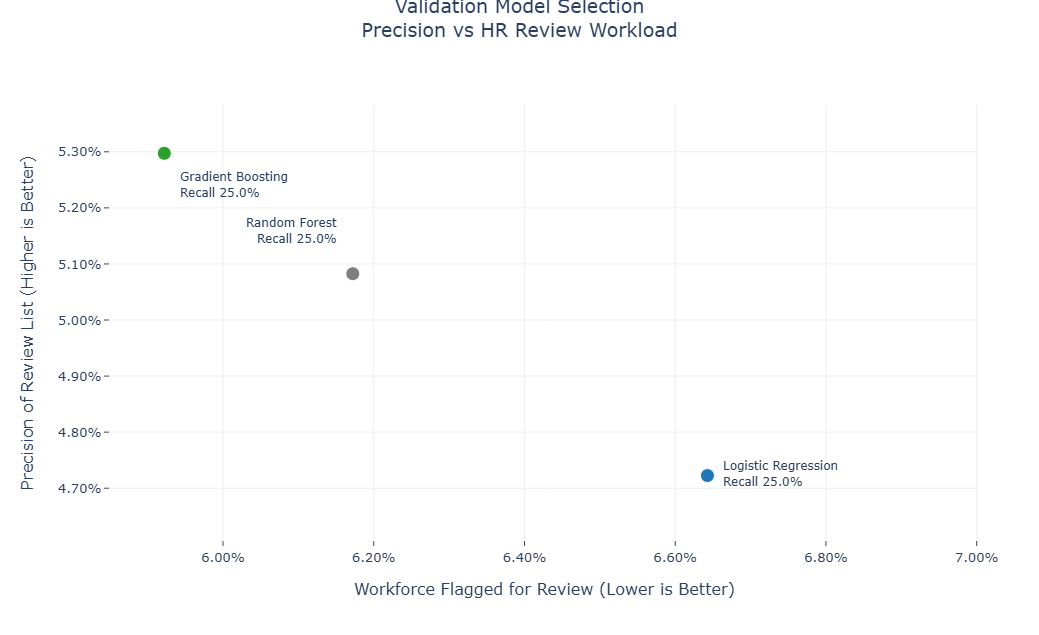

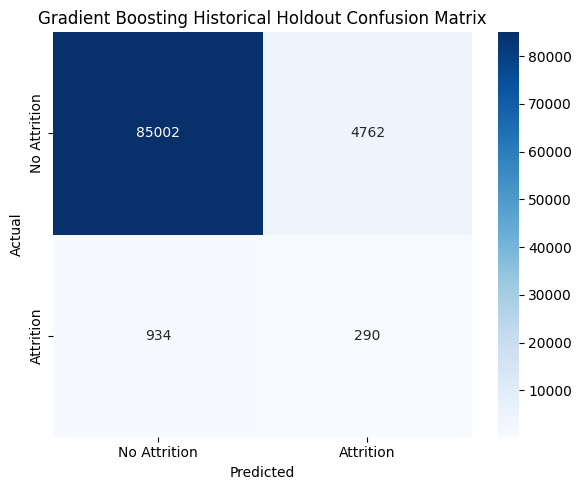

Selected-model historical holdout results by entity (large groups only):


,entity,records,attrition_cases,base_rate,average_precision,precision,recall,flagged_rate,lift
1,06,46770,587,0.0126,0.0372,0.0521,0.2010,0.0484,4.1491
0,01,37566,534,0.0142,0.0437,0.0550,0.2509,0.0649,3.8681
2,08,6494,103,0.0159,0.0823,0.1089,0.3689,0.0537,6.8649


In [31]:
from pathlib import Path


# Use validation to fix the model and cutoff before the historical check.
validation_comparison_df = pd.DataFrame([
    lr_valid_metrics,
    rf_valid_metrics,
    gbm_valid_metrics,
])
validation_comparison_df["development_overfit_gap"] = [
    lr_cv_overfit_gap,
    rf_cv_overfit_gap,
    gbm_cv_overfit_gap,
]
validation_comparison_df["meets_recall_target"] = (
    validation_comparison_df["recall"] >= target_recall
)
validation_comparison_df["passes_overfit_guard"] = (
    validation_comparison_df["development_overfit_gap"] <= 0.05
)
eligible_models = validation_comparison_df.loc[
    validation_comparison_df["meets_recall_target"]
    & validation_comparison_df["passes_overfit_guard"]
].copy()

if len(eligible_models) > 0:
    selected_model_name = eligible_models.sort_values(
        ["precision", "flagged_rate", "average_precision"],
        ascending=[False, True, False],
    ).iloc[0]["model"]
    selection_reason = (
        "highest validation precision among models meeting the 25% recall target "
        "and the development overfitting safeguard; flagged rate and average "
        "precision break close results"
    )
else:
    selected_model_name = validation_comparison_df.sort_values(
        ["recall", "precision", "flagged_rate", "average_precision"],
        ascending=[False, False, True, False],
    ).iloc[0]["model"]
    selection_reason = (
        "fallback: highest validation recall because no model met the target"
    )

model_artifacts = {
    "Logistic Regression": {"model": lr_model, "threshold": lr_threshold},
    "Random Forest": {"model": rf_model, "threshold": rf_threshold},
    "Gradient Boosting": {"model": gbm_model, "threshold": gbm_threshold},
}
selected_artifacts = model_artifacts[selected_model_name]
best_model = selected_artifacts["model"]
best_threshold = selected_artifacts["threshold"]

print("Validation comparison used for model selection:")
display(validation_comparison_df.round(4))
print("Selected final model:", selected_model_name)
print("Selection reason:", selection_reason)
print("Selected operating threshold:", best_threshold)

# Replay the already-reviewed holdout; this is historical evidence.
lr_test_prob = lr_model.predict_proba(X_test[lr_model_features])[:, 1]
rf_test_prob = rf_model.predict_proba(X_test[rf_model_features])[:, 1]
gbm_test_prob = gbm_model.predict_proba(X_test[gbm_model_features])[:, 1]

lr_test_metrics, lr_test_pred = evaluate_at_threshold(
    "Logistic Regression", y_test, lr_test_prob, lr_threshold
)
rf_test_metrics, rf_test_pred = evaluate_at_threshold(
    "Random Forest", y_test, rf_test_prob, rf_threshold
)
gbm_test_metrics, gbm_test_pred = evaluate_at_threshold(
    "Gradient Boosting", y_test, gbm_test_prob, gbm_threshold
)
test_comparison_df = pd.DataFrame([
    lr_test_metrics,
    rf_test_metrics,
    gbm_test_metrics,
])

selected_test_predictions = {
    "Logistic Regression": (lr_test_prob, lr_test_pred, lr_test_metrics),
    "Random Forest": (rf_test_prob, rf_test_pred, rf_test_metrics),
    "Gradient Boosting": (gbm_test_prob, gbm_test_pred, gbm_test_metrics),
}
y_test_prob, y_test_pred, selected_test_metrics = selected_test_predictions[
    selected_model_name
]
y_valid_prob = {
    "Logistic Regression": lr_valid_prob,
    "Random Forest": rf_valid_prob,
    "Gradient Boosting": gbm_valid_prob,
}[selected_model_name]
y_valid_pred = {
    "Logistic Regression": lr_valid_pred,
    "Random Forest": rf_valid_pred,
    "Gradient Boosting": gbm_valid_pred,
}[selected_model_name]

print("Historical holdout comparison (replayed after selection):")
display(test_comparison_df.round(4))
print(f"{selected_model_name} classification report on historical holdout:")
print(classification_report(y_test, y_test_pred, zero_division=0))

# Summarize overfitting and performance across calendar snapshots.
overfitting_diagnostic_df = pd.DataFrame({
    "model": ["Logistic Regression", "Random Forest", "Gradient Boosting"],
    "cv_train_average_precision": [
        lr_cv_train_ap, rf_cv_train_ap, gbm_cv_train_ap
    ],
    "cv_validation_average_precision": [
        lr_cv_validation_ap, rf_cv_validation_ap, gbm_cv_validation_ap
    ],
    "cv_overfit_gap": [
        lr_cv_overfit_gap, rf_cv_overfit_gap, gbm_cv_overfit_gap
    ],
    "fixed_validation_average_precision": [
        lr_valid_metrics["average_precision"],
        rf_valid_metrics["average_precision"],
        gbm_valid_metrics["average_precision"],
    ],
    "final_test_average_precision": [
        lr_test_metrics["average_precision"],
        rf_test_metrics["average_precision"],
        gbm_test_metrics["average_precision"],
    ],
})
overfitting_diagnostic_df["diagnostic"] = np.select(
    [
        overfitting_diagnostic_df["cv_overfit_gap"] > 0.05,
        overfitting_diagnostic_df["cv_overfit_gap"] > 0.02,
    ],
    ["Large train-development gap", "Moderate train-development gap"],
    default="Limited train-development gap",
)


def best_search_snapshot_rows(search, model_name):
    rows = []
    selected_index = getattr(search, "selected_index_", search.best_index_)
    for fold_index, summary in tuning_snapshot_summary.iterrows():
        rows.append({
            "model": model_name,
            "stage": "Development check",
            "snapshot": pd.Timestamp(summary["validation_date"]),
            "average_precision": float(
                search.cv_results_[f"split{fold_index}_test_score"][
                    selected_index
                ]
            ),
        })
    return rows


calendar_performance_rows = []
for search, model_name in [
    (lr_search, "Logistic Regression"),
    (rf_search, "Random Forest"),
    (gbm_search, "Gradient Boosting"),
]:
    calendar_performance_rows.extend(
        best_search_snapshot_rows(search, model_name)
    )

for model_name, valid_metrics, test_metrics in [
    ("Logistic Regression", lr_valid_metrics, lr_test_metrics),
    ("Random Forest", rf_valid_metrics, rf_test_metrics),
    ("Gradient Boosting", gbm_valid_metrics, gbm_test_metrics),
]:
    calendar_performance_rows.extend([
        {
            "model": model_name,
            "stage": "Main validation",
            "snapshot": validation_date,
            "average_precision": valid_metrics["average_precision"],
        },
        {
            "model": model_name,
            "stage": "Historical holdout",
            "snapshot": test_date,
            "average_precision": test_metrics["average_precision"],
        },
    ])

calendar_performance_df = pd.DataFrame(calendar_performance_rows).sort_values(
    ["snapshot", "model"]
)
print("Overfitting diagnostic:")
display(overfitting_diagnostic_df.round(5))
print("Average precision across calendar snapshots:")
display(calendar_performance_df.round(5))

# Compare review-list precision with the amount of HR review work required.
import plotly.graph_objects as go

model_colors = {
    "Logistic Regression": "#1f77b4",
    "Random Forest": "#7f7f7f",
    "Gradient Boosting": "#2ca02c",
}
model_selection_fig = go.Figure()
label_positions = {
    "Gradient Boosting": (14, -14, "left", "top"),
    "Random Forest": (-14, 26, "right", "bottom"),
    "Logistic Regression": (14, 2, "left", "middle"),
}
for _, row in validation_comparison_df.iterrows():
    model_selection_fig.add_trace(go.Scatter(
        x=[row["flagged_rate"]],
        y=[row["precision"]],
        mode="markers",
        name=row["model"],
        marker=dict(size=14, color=model_colors[row["model"]],
                    line=dict(color="white", width=1)),
        customdata=[[
            row["model"], row["recall"], row["tp"] + row["fp"],
            row["average_precision"], row["development_overfit_gap"],
        ]],
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>Workforce flagged: %{x:.2%}"
            "<br>Precision: %{y:.2%}<br>Recall: %{customdata[1]:.2%}"
            "<br>Records flagged: %{customdata[2]:,.0f}"
            "<br>Average precision: %{customdata[3]:.2%}"
            "<br>Development AP gap: %{customdata[4]:.2%}<extra></extra>"
        ),
        showlegend=False,
    ))
    dx, dy, ha, va = label_positions[row["model"]]
    model_selection_fig.add_annotation(
        x=row["flagged_rate"], y=row["precision"],
        text=f"{row['model']}<br>Recall {row['recall']:.1%}",
        showarrow=False, xshift=dx, yshift=dy, xanchor=ha, yanchor=va,
        align="left" if ha == "left" else "right", font=dict(size=12),
    )
flagged_span = max(float(validation_comparison_df["flagged_rate"].max()
                         - validation_comparison_df["flagged_rate"].min()), 0.001)
precision_span = max(float(validation_comparison_df["precision"].max()
                           - validation_comparison_df["precision"].min()), 0.001)
model_selection_fig.update_layout(
    title=dict(text="Validation Model Selection<br>Precision vs HR Review Workload",
               x=0.5, y=0.98, xanchor="center", yanchor="top", font=dict(size=19)),
    template="plotly_white",
    width=1050,
    height=620,
    font=dict(size=13),
    margin=dict(l=110, r=60, t=105, b=95),
    hovermode="closest",
    xaxis=dict(
        title="Workforce Flagged for Review (Lower is Better)", tickformat=".2%",
        range=[validation_comparison_df["flagged_rate"].min() - flagged_span * 0.10,
               validation_comparison_df["flagged_rate"].max() + flagged_span * 0.50],
        gridcolor="#eeeeee", automargin=True,
        title_standoff=20, ticks="outside", ticklen=5,
    ),
    yaxis=dict(
        title="Precision of Review List (Higher is Better)", tickformat=".2%",
        range=[validation_comparison_df["precision"].min() - precision_span * 0.20,
               validation_comparison_df["precision"].max() + precision_span * 0.15],
        gridcolor="#eeeeee", automargin=True,
        title_standoff=20, ticks="outside", ticklen=5,
    ),
)
model_selection_fig.show()

# Review errors on the already-inspected holdout after this run's validation choice.
selected_test_cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    selected_test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Attrition", "Attrition"],
    yticklabels=["No Attrition", "Attrition"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{selected_model_name} Historical Holdout Confusion Matrix")
plt.tight_layout()
plt.show()


# Look for historical performance differences across large entities.
subgroup_frame = pd.DataFrame({
    "entity": X_test["entity"].astype("string").fillna("Missing"),
    "actual": y_test.to_numpy(),
    "score": y_test_prob,
    "flagged": y_test_pred,
})
subgroup_rows = []
for entity_name, group in subgroup_frame.groupby("entity", dropna=False):
    if len(group) < 1_000 or group["actual"].sum() < 10:
        continue
    subgroup_precision = precision_score(
        group["actual"], group["flagged"], zero_division=0
    )
    subgroup_rows.append({
        "entity": entity_name,
        "records": len(group),
        "attrition_cases": int(group["actual"].sum()),
        "base_rate": group["actual"].mean(),
        "average_precision": average_precision_score(
            group["actual"], group["score"]
        ),
        "precision": subgroup_precision,
        "recall": recall_score(
            group["actual"], group["flagged"], zero_division=0
        ),
        "flagged_rate": group["flagged"].mean(),
        "lift": (
            subgroup_precision / group["actual"].mean()
            if group["actual"].mean() > 0 else np.nan
        ),
    })
subgroup_test_df = pd.DataFrame(subgroup_rows).sort_values(
    "records", ascending=False
)
print("Selected-model historical holdout results by entity (large groups only):")
display(subgroup_test_df.round(4))


**The simpler Gradient Boosting model wins under the existing selection rule.** Its development gap is **3.77 percentage points**, compared with **2.17** for Logistic Regression and **6.60** for Random Forest. Among eligible models, boosting has the higher validation precision: **5.30%**, versus **4.72%** for Logistic Regression.

Boosting requires **5,399 validation reviews**, **657 fewer (10.8%)** than Logistic Regression, while both capture **286 of 1,142 cases**. Validation AP also improves, from **3.36%** to **3.75%**.

After fixing the choice and cutoff, I replay the already-reviewed January 2026 holdout. Boosting captures **290 of 1,224 cases (23.7%)**, with **5.74% precision** and **5.6% listed**. Historical AP is **4.26%**, against a **1.35%** exit rate.

January did not choose the configuration. Because it has already been inspected during project development, this is historical evidence rather than independent confirmation.

**The validation improvement does not carry through consistently to January.** Boosting's historical recall is **23.7%**, versus **25.2%** for Logistic Regression; precision is **5.74%**, versus **5.87%**. The 25% target was set on validation and is not guaranteed in later months. I retain the prespecified validation-based choice, keep Logistic Regression as a benchmark, and require a later untouched period before claiming that boosting performs better over time.

### 13.1 Comparing the Review Workload

All three validation lists capture the same 286 cases. Gradient Boosting requires **657 fewer reviews** than Logistic Regression, a **10.8% reduction**, and has higher review-list precision. Random Forest remains ineligible because its development gap exceeds five percentage points. This chart summarizes the existing selection; it does not revise models or cutoffs.

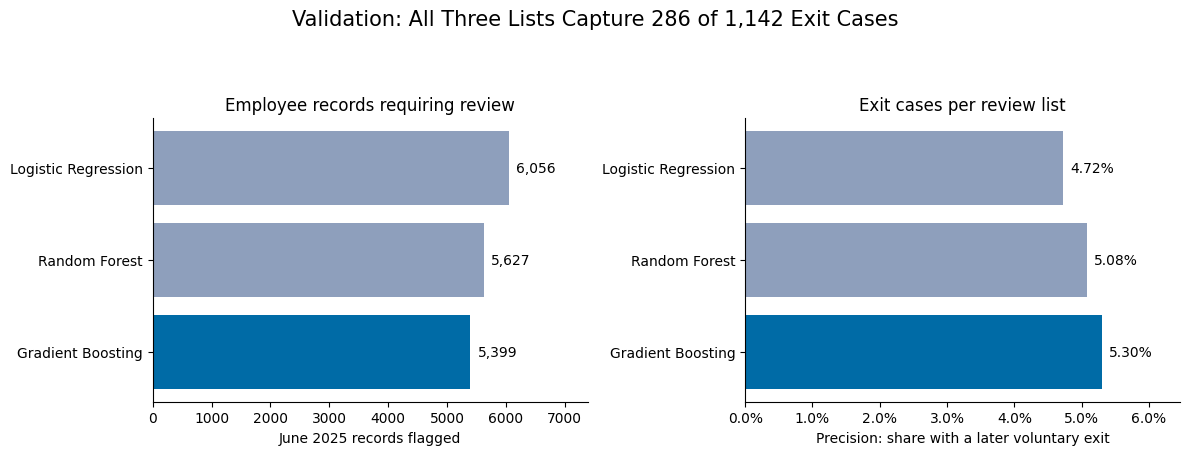

In [32]:
# Compare models at the same validation case-capture target.
review_plot = validation_comparison_df.copy()
review_plot["reviews"] = review_plot["tp"] + review_plot["fp"]
plot_colors = ["#8E9FBC" if name != "Gradient Boosting" else "#006BA6"
               for name in review_plot["model"]]
comparison_fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, field, title, formatter in [
    (axes[0], "reviews", "Employee records requiring review", lambda x: f"{x:,.0f}"),
    (axes[1], "precision", "Exit cases per review list", lambda x: f"{x:.2%}"),
]:
    ax.barh(review_plot["model"], review_plot[field], color=plot_colors)
    ax.invert_yaxis()
    ax.set_xlim(0, review_plot[field].max()*1.22)
    for i, value in enumerate(review_plot[field]):
        ax.text(value+review_plot[field].max()*.02, i, formatter(value), va="center")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_xlabel("June 2025 records flagged")
axes[1].set_xlabel("Precision: share with a later voluntary exit")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
comparison_fig.suptitle("Validation: All Three Lists Capture 286 of 1,142 Exit Cases", fontsize=15)
comparison_fig.tight_layout(rect=[0, 0, 1, .90])
plt.show()

### 13.2 Understanding the Errors and Group Differences

The historical list contains **290 records with a later voluntary exit** and **4,762 without that target exit**. It misses **934 exit cases**. Most listed records do not have the target outcome, and most exit cases remain outside the list.

Across the large reported entities, recall ranges from **20.1% to 36.9%**, with lift from **3.9 to 6.9**. I would investigate these differences before operational use. They do not establish fairness or future consistency.

### 13.3 What This Analysis Can and Cannot Support

The model provides a relative ranking and a review list. Its scores are not calibrated departure probabilities, its feature relationships do not establish causes, and the project has not measured an intervention's effect on retention. Listed employees need context and support rather than assumptions about their plans.

The evidence also has practical limits. There are only two development checks, employee-months repeat individuals, and the historical holdout has already been inspected. Salary definitions, role eligibility and scoring-time data availability need review. A smaller training gap is encouraging evidence under my rule, but it does not guarantee future stability.

Before operational use, I would evaluate a later untouched period with complete outcomes and investigate results across sufficiently large workforce groups.

### 13.4 Assessing Statistical Uncertainty

The following **95% Wilson intervals** quantify binomial sampling uncertainty for the selected model's January historical recall and precision. They assume a fixed model and cutoff and independent, comparable outcomes in this one snapshot. This is a working approximation: shared managers and local conditions can create dependence, and prior inspection of January limits independent confirmation.

These are not time-stability guarantees, paired tests that boosting beats Logistic Regression, or causal statements. A 95% interval describes a procedure's long-run coverage under its assumptions; it is not a 95% probability that a fixed population value lies in this realized interval. Two-fold AP standard deviations elsewhere describe variation across checks and are not confidence intervals.

In [33]:
# Approximate uncertainty for one historical snapshot, using aggregate counts.
from statistics import NormalDist

def wilson_interval(successes, trials, confidence=0.95):
    """Wilson score interval under a binomial working assumption."""
    z = NormalDist().inv_cdf((1+confidence)/2)
    p = successes / trials
    denominator = 1 + z*z/trials
    center = (p + z*z/(2*trials)) / denominator
    half_width = z*np.sqrt(p*(1-p)/trials + z*z/(4*trials*trials)) / denominator
    return center-half_width, center+half_width

historical_row = test_comparison_df.set_index("model").loc["Gradient Boosting"]
uncertainty_rows = []
for metric, denominator in [
    ("Recall: exit cases captured", int(historical_row["tp"] + historical_row["fn"])),
    ("Precision: exits among reviewed", int(historical_row["tp"] + historical_row["fp"])),
]:
    numerator = int(historical_row["tp"])
    low, high = wilson_interval(numerator, denominator)
    uncertainty_rows.append({"Historical measure": metric, "Cases": numerator,
        "Denominator": denominator, "Observed": numerator/denominator,
        "95% lower": low, "95% upper": high})
historical_uncertainty = pd.DataFrame(uncertainty_rows)
display(historical_uncertainty.style.format({"Observed": "{:.1%}",
    "95% lower": "{:.1%}", "95% upper": "{:.1%}"}))

,Historical measure,Cases,Denominator,Observed,95% lower,95% upper
0,Recall: exit cases captured,290,1224,23.7%,21.4%,26.2%
1,Precision: exits among reviewed,290,5052,5.7%,5.1%,6.4%


The approximate January recall interval includes the 25% validation target, but that does not establish stable target achievement or equivalence between models. The comparison between classifiers uses the same employees, so an independent-proportions significance test would be inappropriate. I retain the validation-based choice and would assess paired predictions and later untouched outcomes before claiming a general advantage.

## 14. Explaining the Selected Model and Scoring the Current Workforce

For Gradient Boosting, I use **permutation importance**: shuffle one input and measure how much validation AP changes. A larger decrease suggests that the fitted model relies more on that input for ranking in this sample. This is not a coefficient, does not establish whether higher values increase risk, and does not identify causes. Correlated inputs can share information, making individual importance harder to interpret.

I score **90,493 employee records from September 30, 2026**. The validation cutoff puts **4,478 employees (4.9%)** in High and **23,609 (26.1%)** in Medium. Medium starts at half the High cutoff as a monitoring convention, not a separately validated intervention tier.

These are review-priority bands. Scores are not calibrated departure probabilities or expected exit counts.

Permutation estimates here use three shuffles and a sample of up to 20,000 validation records. I treat them as exploratory sensitivity checks, not stable effect sizes or inferential tests; exact contributions can depend on sampling and correlated inputs.

In this run, only salary and tenure have positive mean importance estimates. Negative estimates for the other inputs mean the shuffled version scored better in this check; they do not mean those inputs protect against attrition. This mixed result calls for further checks before presenting individual fields as reliable drivers.


In [34]:
# Translate the selected model's feature results into readable labels.
preprocess_fitted = best_model.named_steps["preprocess"]
clf_fitted = best_model.named_steps["clf"]

feature_names = list(final_num_features)
if len(final_cat_features) > 0 and "cat" in preprocess_fitted.named_transformers_:
    cat_transformer = preprocess_fitted.named_transformers_["cat"]
    if hasattr(cat_transformer, "named_steps") and "onehot" in cat_transformer.named_steps:
        cat_ohe = cat_transformer.named_steps["onehot"]
        feature_names = feature_names + list(
            cat_ohe.get_feature_names_out(final_cat_features)
        )

if hasattr(clf_fitted, "coef_"):
    importance_df = (
        pd.DataFrame({
            "feature": feature_names,
            "importance": clf_fitted.coef_[0],
            "importance_type": "logistic_coefficient",
        })
        .assign(abs_importance=lambda d: d["importance"].abs())
        .sort_values("abs_importance", ascending=False)
    )
elif hasattr(clf_fitted, "feature_importances_"):
    importance_df = (
        pd.DataFrame({
            "feature": feature_names,
            "importance": clf_fitted.feature_importances_,
            "importance_type": "random_forest_feature_importance",
        })
        .assign(abs_importance=lambda d: d["importance"].abs())
        .sort_values("importance", ascending=False)
    )
else:
    # Shuffle one feature at a time and measure the change in validation ranking.
    from sklearn.inspection import permutation_importance

    permutation = permutation_importance(
        best_model,
        X_valid[final_model_features],
        y_valid,
        scoring="average_precision",
        n_repeats=3,
        random_state=RANDOM_STATE,
        n_jobs=1,
        max_samples=min(20000, len(X_valid)),
    )
    importance_df = (
        pd.DataFrame({
            "feature": final_model_features,
            "importance": permutation.importances_mean,
            "importance_type": "permutation_importance",
        })
        .assign(abs_importance=lambda d: d["importance"].abs())
        .sort_values("abs_importance", ascending=False)
    )

coef_df = importance_df.copy()

print("Selected model:", selected_model_name)
print("Selected feature set:", final_feature_set_name)
print("Top model drivers by absolute importance:")
display(importance_df.head(15))

# Show how the fitted weights move the model score higher or lower.
if selected_model_name == "Logistic Regression":
    coefficient_labels = {
        "annual_salary": "Annual salary",
        "tenure_months": "Employee tenure",
        "low_performer": "Low-performer status",
        "mgr_avg_team_tenure": "Manager team tenure",
        "mgr_attrition_6mo_rate": "Manager turnover (6 mo)",
        "mgr_attrition_12mo_rate": "Manager turnover (12 mo)",
        "underpaid_flag": "Pay below peer benchmark",
        "high_mgr_attrition": "Any prior manager turnover",
    }
    coefficient_plot = importance_df.copy()
    coefficient_plot["feature_label"] = coefficient_plot["feature"].map(
        coefficient_labels
    ).fillna(coefficient_plot["feature"])
    coefficient_plot = coefficient_plot.sort_values("importance")
    coefficient_colors = np.where(
        coefficient_plot["importance"] > 0,
        "#CB333B",
        "#006BA6",
    )

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(
        coefficient_plot["feature_label"],
        coefficient_plot["importance"],
        color=coefficient_colors,
    )
    ax.axvline(0, color="#5A5A5A", linewidth=1)
    ax.set_title("Selected Logistic Regression Coefficients")
    ax.set_xlabel("Standardized Coefficient (Direction of Model Score)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.15)
    sns.despine(ax=ax)
    plt.tight_layout()

    plt.show()


Selected model: Gradient Boosting
Selected feature set: All candidate numeric features
Top model drivers by absolute importance:


,feature,importance,importance_type,abs_importance
0,annual_salary,0.013829,permutation_importance,0.013829
12,compa_tenure_interaction,-0.005044,permutation_importance,0.005044
10,underpaid_flag,-0.004881,permutation_importance,0.004881
1,compa_ratio,-0.004688,permutation_importance,0.004688
4,low_performer,-0.004673,permutation_importance,0.004673
11,high_mgr_attrition,-0.004673,permutation_importance,0.004673
7,mgr_low_perf_pct,-0.004651,permutation_importance,0.004651
6,mgr_avg_team_tenure,-0.004128,permutation_importance,0.004128
8,mgr_attrition_6mo_rate,-0.003850,permutation_importance,0.003850
9,mgr_attrition_12mo_rate,-0.002736,permutation_importance,0.002736


In [35]:
# Score the latest employee snapshot to create the current HR review list.
latest_snapshot = df.loc[
    df["snapshot_date"] == df["snapshot_date"].max()
].copy()

id_cols = ["nuid", "manager_nuid"]
available_id_cols = [col for col in id_cols if col in latest_snapshot.columns]
latest_ids = latest_snapshot[available_id_cols].copy() if available_id_cols else pd.DataFrame(index=latest_snapshot.index)

latest_snapshot_model = latest_snapshot.copy()
latest_snapshot_model["snapshot_date"] = pd.to_datetime(latest_snapshot_model["snapshot_date"])

latest_snapshot_model["underpaid_flag"] = (
    latest_snapshot_model["compa_ratio"] < 1
).astype(int)

latest_snapshot_model["high_mgr_attrition"] = (
    latest_snapshot_model["mgr_attrition_12mo_rate"].fillna(0) > 0
).astype(int)

latest_snapshot_model["compa_tenure_interaction"] = (
    latest_snapshot_model["compa_ratio"] * latest_snapshot_model["tenure_months"]
)

latest_snapshot_model = latest_snapshot_model.replace([np.inf, -np.inf], np.nan)

missing_score_features = [col for col in final_model_features if col not in latest_snapshot_model.columns]
if missing_score_features:
    raise ValueError(f"Scoring data is missing model features: {missing_score_features}")

latest_x = latest_snapshot_model[final_model_features].copy()
print("Scoring dataset shape:", latest_x.shape)

latest_snapshot["attrition_risk"] = best_model.predict_proba(latest_x)[:, 1]

if available_id_cols:
    latest_snapshot[available_id_cols] = latest_ids

high_threshold = best_threshold
# Reuse the validation cutoff for High; Medium is a monitoring convention.
medium_threshold = high_threshold * 0.5

latest_snapshot["risk_band"] = np.select(
    [
        latest_snapshot["attrition_risk"] >= high_threshold,
        latest_snapshot["attrition_risk"] >= medium_threshold,
    ],
    ["High", "Medium"],
    default="Low",
)

risk_band_summary = (
    latest_snapshot["risk_band"]
    .value_counts(dropna=False)
    .rename_axis("risk_band")
    .reset_index(name="employees")
)
risk_band_summary["share"] = risk_band_summary["employees"] / len(latest_snapshot)

print("High threshold:", high_threshold)
print("Medium threshold:", medium_threshold)
display(risk_band_summary)


Scoring dataset shape: (90493, 13)
High threshold: 0.7653947818217843
Medium threshold: 0.38269739091089217


,risk_band,employees,share
0,Low,62406,0.689622
1,Medium,23609,0.260893
2,High,4478,0.049484


## 15. Saving the Internal Handoff

An authorized rerun writes five internal CSV exports to `outputs`: current employee scores, feature checks, validation results, historical results and the split summary. They support the separate HR insights workflow. They are not included in this submission folder, and employee-level scored data should remain within the approved internal environment.

This submission contains the executed notebook, the nontechnical README and the aggregate figures used by that README. The original working notebook, development evidence and backups remain outside the submission folder. For operational use, the fitted pipeline, environment and model metadata would also need to be preserved.

In [36]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the five files that connect training results to the HR story.
latest_snapshot.to_csv(
    output_dir / "attrition_latest_snapshot_scored.csv", index=False
)
importance_df.to_csv(
    output_dir / "attrition_model_feature_importance.csv", index=False
)
validation_comparison_df.to_csv(
    output_dir / "model_validation_comparison.csv", index=False
)
test_comparison_df.to_csv(
    output_dir / "model_test_comparison.csv", index=False
)
model_split_summary_df.to_csv(
    output_dir / "model_split_summary.csv", index=False
)

print("Saved outputs used by attrition_insights_reg:")
print(output_dir / "attrition_latest_snapshot_scored.csv")
print(output_dir / "attrition_model_feature_importance.csv")
print(output_dir / "model_validation_comparison.csv")
print(output_dir / "model_test_comparison.csv")
print(output_dir / "model_split_summary.csv")

Saved outputs used by attrition_insights_reg:
outputs\attrition_latest_snapshot_scored.csv
outputs\attrition_model_feature_importance.csv
outputs\model_validation_comparison.csv
outputs\model_test_comparison.csv
outputs\model_split_summary.csv


### 15.1 Following the Model as the Workforce Changes

Deployment is outside this capstone, but the workflow would need ongoing checks:

1. **Check each scoring file.** Verify dates, record counts, duplicates, missing values and unusual ranges, especially salary and pay position. Investigate sudden changes in band sizes.
2. **Measure results when outcomes are complete.** Once the six-month window and source coverage are complete, recalculate AP, cases captured, precision, lift and review workload.
3. **Look across workforce groups.** Compare sufficiently large groups and investigate differences in data quality, changing conditions or potential unfair impact.
4. **Keep a model record.** Save the dates, inputs, settings and cutoff for each run. Persistent deterioration or unexplained changes should trigger review, not an automatic model change.

The aim is to keep the ranking useful and the review process manageable as the workforce changes.

### 15.2 The Decisions I Would Make Next

First, I would ask HR whether **5,399 validation reviews** is feasible for capturing about one-quarter of cases. The current snapshot has a different list size, so historical workload should not be assumed to repeat exactly.

Next, I would verify eligibility, salary annualization, hours, pay benchmarks and missing manager history with the data owners. Finally, I would freeze the model and cutoff, evaluate a later untouched period, and review group differences before agreeing on a supportive pilot.

## 16. What I Learned and What It Means for HR

Simplifying Gradient Boosting improved the balance between ranking quality and overfitting control. On June validation, it captures **25.0% of exit cases**, with **5.30% precision**, while listing **5.9% of employees**. The list has **4.2 times** the workforce exit concentration.

Compared with Logistic Regression on the same data, it requires **657 fewer reviews (10.8% fewer)** at approximately the same case-capture target. This is an improvement in prioritization, not evidence that exits were prevented.

The current scores and feature-importance table help frame follow-up questions. They should be combined with HR context and checks of pay definitions, schedules, job mix and missing manager history. Aggregated scores combine group size with relative rankings; they are not predicted exit counts or measures of department quality.

My next step is to verify the data, test the fixed approach on new outcomes, and agree with HR on a manageable, supportive review process. The effect of any retention action still needs to be evaluated.

The January historical replay is a reminder that this gain is specific to validation: boosting captures **23.7%** of historical cases compared with **25.2%** for Logistic Regression. I would not claim a general performance advantage or recommend deployment from these results alone.